In [ ]:

!pip -q install spacy scikit-learn pandas matplotlib seaborn reportlab
!python -m spacy download en_core_web_sm


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 22.9 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:

import spacy
import pandas as pd
import sklearn
import matplotlib.pyplot as plt

nlp = spacy.load("en_core_web_sm")

print("¡Entorno listo para trabajar!")
print("spaCy:", spacy.__version__)
print("Modelo de inglés:", nlp.meta["name"])
print("scikit-learn:", sklearn.__version__)


¡Entorno listo para trabajar!
spaCy: 3.8.16
Modelo de inglés: core_web_sm
scikit-learn: 1.6.1


In [ ]:

from google.colab import files
import os
import pandas as pd

print("Subí ag_news_train.csv")
archivos = files.upload()

if "ag_news_train.csv" not in archivos:
    print("Todavía falta ag_news_train.csv. Podés ejecutar esta celda cuando lo tengas.")
else:
    train_df = pd.read_csv("ag_news_train.csv")
    print("Dataset cargado:", train_df.shape)
    display(train_df.head())


Subí ag_news_train.csv


KeyboardInterrupt: 

In [ ]:

import re
import spacy

nlp = spacy.load("en_core_web_sm")

def clean_text(text):
    """Normaliza el texto y elimina ruido básico."""
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


def preprocess_text(text, remove_stopwords=False):
    """Limpia, tokeniza y lematiza el texto con spaCy."""
    cleaned = clean_text(text)
    doc = nlp(cleaned)

    tokens = []
    for token in doc:
        if token.is_space or token.is_punct:
            continue
        if not token.lemma_.strip():
            continue
        if remove_stopwords and token.is_stop:
            continue

        tokens.append(token.lemma_.lower())

    return " ".join(tokens)


ejemplo = "The companies are running successful businesses!"
print("Original:", ejemplo)
print("Lematizado:", preprocess_text(ejemplo))
print("Lematizado sin stop-words:",
      preprocess_text(ejemplo, remove_stopwords=True))


Original: The companies are running successful businesses!
Lematizado: the company be run successful business
Lematizado sin stop-words: company run successful business


In [ ]:

import os

print("Archivos disponibles en Colab:")
print(os.listdir("/content"))


Archivos disponibles en Colab:
['.config', 'ag_news_test (1).csv', 'README (1).md', 'cargar_dataset (1).py', 'ag_news_train (1).csv', 'sample_data']


In [ ]:

import pandas as pd

# Cargar los dos archivos con sus nombres reales
train_df = pd.read_csv("/content/ag_news_train (1).csv")
test_df = pd.read_csv("/content/ag_news_test (1).csv")

print("ENTRENAMIENTO")
print("Dimensiones:", train_df.shape)
print("Columnas:", train_df.columns.tolist())
display(train_df.head())

print("\nPRUEBA")
print("Dimensiones:", test_df.shape)
print("Columnas:", test_df.columns.tolist())
display(test_df.head())


ENTRENAMIENTO
Dimensiones: (8000, 2)
Columnas: ['text', 'label']


,text,label
0,"Red Hat Appoints New CFO. September 2, 2004 --...",Sci_Tech
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",Sci_Tech
2,Radio Outage Grounds West Coast Flights. Airpo...,Business
3,Hollywood lawsuits to strike Net pirates. Holl...,Sci_Tech
4,Custis Takes Control. Family and Tony Robbins ...,Sports



PRUEBA
Dimensiones: (2000, 2)
Columnas: ['text', 'label']


,text,label
0,BSkyB sees profits rise after strong subscribe...,World
1,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,Business
2,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",Sports
3,"Hackers, spoofers and malware--oh my!. IE expl...",Sci_Tech
4,Ravens #39; Ogden could miss Week 8. Baltimore...,Sports


In [ ]:
# 1. Revisar valores faltantes
print("VALORES FALTANTES")
print("Entrenamiento:")
print(train_df.isnull().sum())

print("\nPrueba:")
print(test_df.isnull().sum())


# 2. Revisar registros duplicados
print("\nREGISTROS DUPLICADOS")
print("Entrenamiento:", train_df.duplicated().sum())
print("Prueba:", test_df.duplicated().sum())


# 3. Revisar las categorías disponibles
print("\nCATEGORÍAS")
print("Entrenamiento:")
print(train_df["label"].value_counts())

print("\nPrueba:")
print(test_df["label"].value_counts())


# 4. Verificar los tipos de datos
print("\nTIPOS DE DATOS")
print(train_df.dtypes)

VALORES FALTANTES
Entrenamiento:
text     0
label    0
dtype: int64

Prueba:
text     0
label    0
dtype: int64

REGISTROS DUPLICADOS
Entrenamiento: 0
Prueba: 0

CATEGORÍAS
Entrenamiento:
label
Sci_Tech    2000
Business    2000
Sports      2000
World       2000
Name: count, dtype: int64

Prueba:
label
World       500
Business    500
Sports      500
Sci_Tech    500
Name: count, dtype: int64

TIPOS DE DATOS
text     object
label    object
dtype: object


In [ ]:

import re
import pandas as pd
import spacy

# Cargar el modelo de inglés
nlp = spacy.load("en_core_web_sm")

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)  # Etiquetas HTML
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)  # URLs
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)  # Emails
    text = re.sub(r"[^a-z0-9\s']", " ", text)  # Caracteres especiales
    text = re.sub(r"\s+", " ", text).strip()

    return text

def process_corpus(texts, batch_size=128):
    cleaned_texts = [clean_text(t) for t in texts]

    lemmas_all = []
    lemmas_no_stop = []
    token_lengths = []

    for doc in nlp.pipe(cleaned_texts, batch_size=batch_size):
        all_tokens = []
        content_tokens = []

        for token in doc:
            if token.is_space or token.is_punct:
                continue
            if not token.lemma_.strip():
                continue

            lemma = token.lemma_.lower()
            all_tokens.append(lemma)

            if not token.is_stop:
                content_tokens.append(lemma)

        lemmas_all.append(" ".join(all_tokens))
        lemmas_no_stop.append(" ".join(content_tokens))
        token_lengths.append(len(all_tokens))

    result = pd.DataFrame({
        "text_clean": cleaned_texts,
        "text_lemmas": lemmas_all,
        "text_lemmas_no_stop": lemmas_no_stop,
        "token_length": token_lengths
    })

    return result

print("Funciones de preprocesamiento definidas correctamente.")


Funciones de preprocesamiento definidas correctamente.


In [ ]:

# Procesar cada conjunto por separado
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Incorporar las columnas procesadas sin modificar las originales
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed],
    axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed],
    axis=1
)

# Comprobar resultados
print("ENTRENAMIENTO")
print("Dimensiones:", train_data.shape)
display(train_data[[
    "label", "text", "text_clean",
    "text_lemmas", "text_lemmas_no_stop", "token_length"
]].head(3))

print("\nPRUEBA")
print("Dimensiones:", test_data.shape)
display(test_data[[
    "label", "text", "text_lemmas_no_stop", "token_length"
]].head(3))


ENTRENAMIENTO
Dimensiones: (8000, 6)


,label,text,text_clean,text_lemmas,text_lemmas_no_stop,token_length
0,Sci_Tech,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september 2 2004 web ...,red hat appoint new cfo september 2 2004 web h...,red hat appoint new cfo september 2 2004 web h...,29
1,Sci_Tech,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roaming deal sprint and ...,sprint sbc in hotspot roam deal sprint and sbc...,sprint sbc hotspot roam deal sprint sbc commun...,33
2,Business,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...,radio outage ground west coast flights airport...,radio outage ground west coast flights airport...,31



PRUEBA
Dimensiones: (2000, 6)


,label,text,text_lemmas_no_stop,token_length
0,World,BSkyB sees profits rise after strong subscribe...,bskyb see profit rise strong subscriber growth...,41
1,Business,Before-the Bell; Rouse Co. Shares Jump. &lt;A ...,bell rouse co share jump lt href target stock ...,61
2,Sports,"Minutemen KO'd by Dukes. HARRISONBURG, Va. -- ...",minutemen ko'd duke harrisonburg va oppose run...,19


In [ ]:

import html
import re

def clean_text(text):
    if pd.isna(text):
        return ""

    # Decodificar entidades HTML antes de eliminar etiquetas
    text = html.unescape(str(text))

    # Eliminar etiquetas HTML
    text = re.sub(r"<[^>]+>", " ", text)

    # Normalizar a minúsculas
    text = text.lower()

    # Eliminar URLs y correos electrónicos
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    # Conservar letras, números, espacios y apóstrofes
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Probar la limpieza con un ejemplo de los datos
ejemplo = "Before-the Bell; Rouse Co. Shares Jump. &lt;A href='https://example.com'&gt;Stock&lt;/A&gt;"
print(clean_text(ejemplo))



before the bell rouse co shares jump stock


In [ ]:

# Volver a procesar los textos con la limpieza corregida
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Reconstruir los datasets procesados
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed],
    axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed],
    axis=1
)

print("Entrenamiento:", train_data.shape)
print("Prueba:", test_data.shape)

print("\nEjemplo de texto limpiado:")
print(train_data.loc[0, "text_clean"])

print("\nEjemplo lematizado sin stop-words:")
print(train_data.loc[0, "text_lemmas_no_stop"])

print("\n¿Hay valores faltantes en las columnas procesadas?")
print(train_data[[
    "text_clean", "text_lemmas",
    "text_lemmas_no_stop", "token_length"
]].isnull().sum())


Entrenamiento: (8000, 6)
Prueba: (2000, 6)

Ejemplo de texto limpiado:
red hat appoints new cfo september 2 2004 web host industry review linux distributor red hat redhat com announced on thursday that it has appointed charles e peters jr

Ejemplo lematizado sin stop-words:
red hat appoint new cfo september 2 2004 web host industry review linux distributor red hat redhat com announce thursday appoint charles e peters jr

¿Hay valores faltantes en las columnas procesadas?
text_clean             0
text_lemmas            0
text_lemmas_no_stop    0
token_length           0
dtype: int64


ESTADÍSTICAS DE LONGITUD
count    8000.000000
mean       25.454375
std         6.622888
min         6.000000
25%        21.000000
50%        25.000000
75%        29.000000
max        74.000000
Name: token_length_no_stop, dtype: float64

Percentil 95 (P95): 36.00
max_len sugerido (redondeado hacia arriba): 36
Documentos con longitud <= max_len: 95.67%


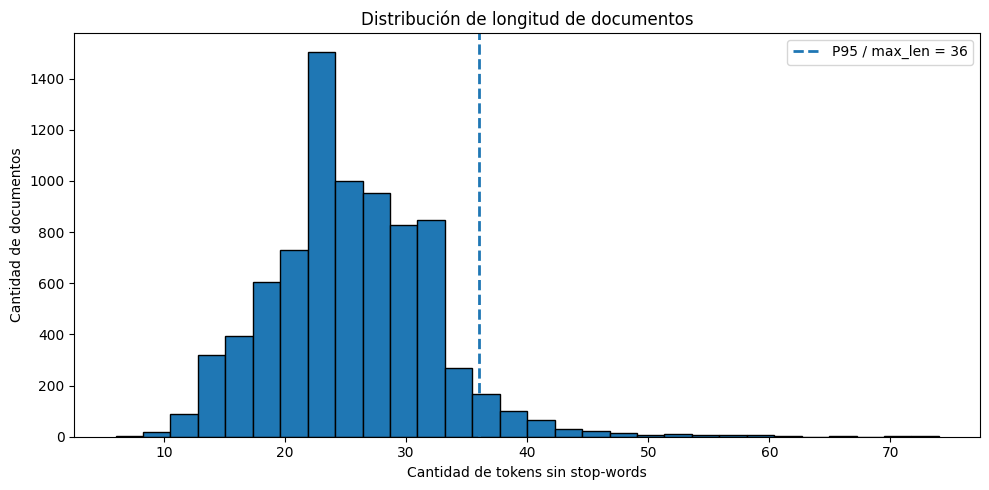

In [ ]:

import matplotlib.pyplot as plt
import numpy as np

# Calcular la cantidad de tokens de la versión sin stop-words
train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"]
    .str.split()
    .str.len()
)

# Estadísticas descriptivas
lengths = train_data["token_length_no_stop"]

p95 = int(np.ceil(lengths.quantile(0.95)))

print("ESTADÍSTICAS DE LONGITUD")
print(lengths.describe())
print(f"\nPercentil 95 (P95): {lengths.quantile(0.95):.2f}")
print(f"max_len sugerido (redondeado hacia arriba): {p95}")
print(f"Documentos con longitud <= max_len: {(lengths <= p95).mean() * 100:.2f}%")

# Histograma
plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=30, edgecolor="black")
plt.axvline(
    p95,
    linestyle="--",
    linewidth=2,
    label=f"P95 / max_len = {p95}"
)
plt.title("Distribución de longitud de documentos")
plt.xlabel("Cantidad de tokens sin stop-words")
plt.ylabel("Cantidad de documentos")
plt.legend()
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

# Usar únicamente el conjunto de entrenamiento
corpus = train_data["text_lemmas_no_stop"].fillna("")

def top_ngrams(texts, ngram_range, top_n=20):
    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        token_pattern=r"(?u)\b\w+\b"
    )

    matrix = vectorizer.fit_transform(texts)
    frequencies = matrix.sum(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        "n_grama": terms,
        "frecuencia": frequencies
    })

    return result.sort_values(
        "frecuencia", ascending=False
    ).head(top_n).reset_index(drop=True)

# Bigramas: combinaciones de dos palabras
bigramas = top_ngrams(corpus, (2, 2), 20)

# Trigramas: combinaciones de tres palabras
trigramas = top_ngrams(corpus, (3, 3), 20)

print("TOP 20 BIGRAMAS")
display(bigramas)

print("\nTOP 20 TRIGRAMAS")
display(trigramas)


TOP 20 BIGRAMAS


,n_grama,frecuencia
0,39 s,2114
1,ap ap,529
2,u s,503
3,new york,419
4,oil price,197
5,united states,167
6,39 t,163
7,york reuters,151
8,prime minister,139
9,afp afp,134



TOP 20 TRIGRAMAS


,n_grama,frecuencia
0,new york reuters,151
1,world 39 s,103
2,39 s large,72
3,quote profile research,69
4,reuters u s,52
5,country 39 s,50
6,company 39 s,46
7,39 s big,44
8,n quote profile,40
9,reuter u s,39


In [ ]:

# Revisar los residuos más frecuentes en los textos
print("Ejemplos que contienen residuos sospechosos:")

for texto in train_data["text_clean"].head(100):
    if "&#" in texto or "href" in texto or "quot" in texto:
        print(texto[:250])


Ejemplos que contienen residuos sospechosos:
driver 39 s license gets new high tech features minnesota will soon begin issuing new driver 39 s licenses that contain high tech features to curb counterfeiting as well as a quot status check quot that will show a driver 39 s immigration status
update 1 warburg pincus to buy 2 75 of kotak mahindra bank the board of india 39 s kotak mahindra bank ltd ktkm bo quote profile research has approved an issue of shares representing a 2 75 percent stake to warburg pincus international llc
he hurt me carolina panthers kickoff returner rod smart aka quot he hate me quot sprained his left knee sunday on a kickoff return in the second quarter against the atlanta falcons
dozens killed in baghdad car bomb more than twenty five people have died after a car bomb exploded in a busy commercial area outside a restaurant in west baghdad husayn al shammari an iraqi journalist told aljazeera quot a car bomb detonated


In [ ]:

import html
import re

def clean_text(text):
    if pd.isna(text):
        return ""

    # Decodificar entidades HTML
    text = html.unescape(str(text))

    # Corregir residuos de entidades HTML que quedaron codificados
    text = re.sub(r"\bquot\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\bamp\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b39\s+s\b", " ", text, flags=re.IGNORECASE)
    text = re.sub(r"\b39\s+t\b", " ", text, flags=re.IGNORECASE)

    # Eliminar etiquetas HTML, URLs y correos
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    # Normalizar texto
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Probar con ejemplos reales
ejemplos = [
    "driver 39 s license gets new high tech features",
    'a quot status check quot',
    "kotak mahindra bank ltd quote profile research"
]

for ejemplo in ejemplos:
    print(clean_text(ejemplo))


driver license gets new high tech features
a status check
kotak mahindra bank ltd quote profile research


In [ ]:

# Reprocesar los conjuntos con la función clean_text corregida
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Reconstruir los datasets, conservando textos originales y etiquetas
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed],
    axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed],
    axis=1
)

# Calcular longitudes sobre la versión sin stop-words
train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"].str.split().str.len()
)

test_data["token_length_no_stop"] = (
    test_data["text_lemmas_no_stop"].str.split().str.len()
)

# Comprobar que los residuos principales hayan desaparecido
print("Ejemplo corregido:")
print(train_data.loc[0, "text_clean"])

print("\nCantidad de registros:")
print("Entrenamiento:", len(train_data))
print("Prueba:", len(test_data))

print("\nColumnas:")
print(train_data.columns.tolist())

print("\nValores faltantes en entrenamiento:")
print(train_data.isnull().sum())


Ejemplo corregido:
red hat appoints new cfo september 2 2004 web host industry review linux distributor red hat redhat com announced on thursday that it has appointed charles e peters jr

Cantidad de registros:
Entrenamiento: 8000
Prueba: 2000

Columnas:
['text', 'label', 'text_clean', 'text_lemmas', 'text_lemmas_no_stop', 'token_length', 'token_length_no_stop']

Valores faltantes en entrenamiento:
text                    0
label                   0
text_clean              0
text_lemmas             0
text_lemmas_no_stop     0
token_length            0
token_length_no_stop    0
dtype: int64


In [ ]:

from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

def top_ngrams(texts, ngram_range, top_n=20):
    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        token_pattern=r"(?u)\b\w+\b"
    )

    matrix = vectorizer.fit_transform(texts)
    frequencies = matrix.sum(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        "n_grama": terms,
        "frecuencia": frequencies
    })

    return result.sort_values(
        "frecuencia", ascending=False
    ).head(top_n).reset_index(drop=True)

# Analizar solo entrenamiento y la versión sin stop-words
corpus = train_data["text_lemmas_no_stop"].fillna("")

bigramas = top_ngrams(corpus, (2, 2), 20)
trigramas = top_ngrams(corpus, (3, 3), 20)

print("TOP 20 BIGRAMAS ACTUALIZADOS")
display(bigramas)

print("\nTOP 20 TRIGRAMAS ACTUALIZADOS")
display(trigramas)


TOP 20 BIGRAMAS ACTUALIZADOS


,n_grama,frecuencia
0,39 s,2114
1,ap ap,529
2,u s,503
3,new york,419
4,oil price,197
5,united states,167
6,39 t,163
7,york reuters,151
8,prime minister,139
9,afp afp,134



TOP 20 TRIGRAMAS ACTUALIZADOS


,n_grama,frecuencia
0,new york reuters,151
1,world 39 s,103
2,39 s large,72
3,quote profile research,69
4,reuters u s,52
5,country 39 s,50
6,company 39 s,46
7,39 s big,44
8,n quote profile,40
9,reuter u s,39


In [ ]:

from collections import Counter

# Contar palabras del corpus de entrenamiento
word_counter = Counter(
    word
    for text in train_data["text_lemmas"].fillna("")
    for word in text.split()
)

# Obtener las 50 palabras más frecuentes
top50 = pd.DataFrame(
    word_counter.most_common(50),
    columns=["palabra", "frecuencia"]
)

# Identificar stop-words usando el vocabulario de spaCy
stop_words = nlp.Defaults.stop_words
top50["es_stopword"] = top50["palabra"].apply(
    lambda palabra: palabra in stop_words
)

print("TOP 50 PALABRAS MÁS FRECUENTES")
display(top50)

cantidad_stopwords = int(top50["es_stopword"].sum())

print("\nRESUMEN")
print("Palabras analizadas:", len(top50))
print("Stop-words dentro del top 50:", cantidad_stopwords)
print("Palabras que no son stop-words:", len(top50) - cantidad_stopwords)


TOP 50 PALABRAS MÁS FRECUENTES


,palabra,frecuencia,es_stopword
0,the,13697,True
1,to,7976,True
2,a,7227,True
3,of,6578,True
4,in,6365,True
5,be,4816,True
6,and,4637,True
7,on,3773,True
8,for,3410,True
9,39,2962,False



RESUMEN
Palabras analizadas: 50
Stop-words dentro del top 50: 38
Palabras que no son stop-words: 12


DOCUMENTOS POR CATEGORÍA


,cantidad
label,
World,2000
Sports,2000
Business,2000
Sci_Tech,2000


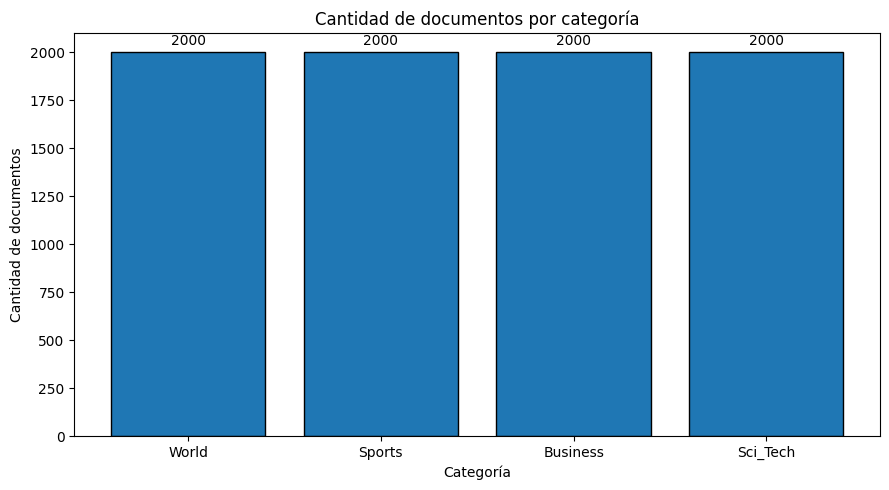

In [ ]:

import matplotlib.pyplot as plt

# Contar documentos por categoría en entrenamiento
category_counts = train_data["label"].value_counts().reindex(
    ["World", "Sports", "Business", "Sci_Tech"]
)

print("DOCUMENTOS POR CATEGORÍA")
display(category_counts.rename("cantidad").to_frame())

# Crear gráfico de barras
plt.figure(figsize=(9, 5))

bars = plt.bar(
    category_counts.index,
    category_counts.values,
    edgecolor="black"
)

plt.title("Cantidad de documentos por categoría")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de documentos")

plt.bar_label(bars, padding=3)
plt.tight_layout()
plt.show()


In [ ]:

# Comparar textos originales entre entrenamiento y prueba
train_texts = set(train_df["text"].dropna().astype(str))
test_texts = set(test_df["text"].dropna().astype(str))

overlap = train_texts.intersection(test_texts)

print("Textos únicos en entrenamiento:", len(train_texts))
print("Textos únicos en prueba:", len(test_texts))
print("Textos compartidos entre ambos conjuntos:", len(overlap))


Textos únicos en entrenamiento: 8000
Textos únicos en prueba: 2000
Textos compartidos entre ambos conjuntos: 0


In [ ]:

import html
import re

def clean_text(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))

    # Eliminar etiquetas HTML, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Corregir residuos frecuentes de apóstrofes codificados
    text = re.sub(r"\b39\s*['’]?\s*s\b", " ", text)
    text = re.sub(r"\b39\s*['’]?\s*t\b", " ", text)

    # Quitar marcadores HTML residuales
    text = re.sub(r"\bquot\b", " ", text)
    text = re.sub(r"\bamp\b", " ", text)

    # Limpiar caracteres y espacios
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

ejemplos = [
    "driver 39 s license",
    "world 39 s largest company",
    "do 39 t know"
]

for ejemplo in ejemplos:
    print(ejemplo, "->", clean_text(ejemplo))


driver 39 s license -> driver license
world 39 s largest company -> world largest company
do 39 t know -> do know


In [ ]:

def clean_text(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))

    # Eliminar etiquetas HTML, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Recuperar contracciones afectadas por la codificación HTML
    text = re.sub(r"\b(\w+)\s+39\s+s\b", r"\1", text)
    text = re.sub(r"\bdo\s+39\s+t\b", "don't", text)
    text = re.sub(r"\bcan\s+39\s+t\b", "can't", text)
    text = re.sub(r"\bwill\s+39\s+t\b", "won't", text)

    # Eliminar residuos de entidades HTML
    text = re.sub(r"\bquot\b", " ", text)
    text = re.sub(r"\bamp\b", " ", text)

    # Limpiar caracteres y espacios
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Comprobar los resultados
for ejemplo in [
    "driver 39 s license",
    "world 39 s largest company",
    "do 39 t know",
    "company 39 s shares"
]:
    print(clean_text(ejemplo))


driver license
world largest company
don't know
company shares


In [ ]:

# Reprocesar entrenamiento y prueba con la función corregida
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed],
    axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed],
    axis=1
)

# Recalcular longitudes sin stop-words
train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"].str.split().str.len()
)

test_data["token_length_no_stop"] = (
    test_data["text_lemmas_no_stop"].str.split().str.len()
)

# Revisar posibles residuos
print("Dimensiones:")
print("Entrenamiento:", train_data.shape)
print("Prueba:", test_data.shape)

print("\nCantidad de textos que contienen '39':")
print(train_data["text_clean"].str.contains(
    r"\b39\b", regex=True
).sum())

print("\nCantidad de textos que contienen 'quot':")
print(train_data["text_clean"].str.contains(
    r"\bquot\b", case=False, regex=True
).sum())

print("\nEjemplos actualizados:")
display(train_data[["text", "text_clean"]].head(5))


Dimensiones:
Entrenamiento: (8000, 7)
Prueba: (2000, 7)

Cantidad de textos que contienen '39':
2019

Cantidad de textos que contienen 'quot':
0

Ejemplos actualizados:


,text,text_clean
0,"Red Hat Appoints New CFO. September 2, 2004 --...",red hat appoints new cfo september 2 2004 web ...
1,"Sprint, SBC In Hotspot Roaming Deal. Sprint an...",sprint sbc in hotspot roaming deal sprint and ...
2,Radio Outage Grounds West Coast Flights. Airpo...,radio outage grounds west coast flights airpor...
3,Hollywood lawsuits to strike Net pirates. Holl...,hollywood lawsuits to strike net pirates holly...
4,Custis Takes Control. Family and Tony Robbins ...,custis takes control family and tony robbins h...


In [ ]:

# Mostrar ejemplos de textos que todavía contienen el número 39
con_39 = train_data[
    train_data["text_clean"].str.contains(r"\b39\b", regex=True, na=False)
]

print("Cantidad de textos con 39:", len(con_39))

for texto in con_39["text_clean"].head(10):
    print("-", texto[:300])


Cantidad de textos con 39: 2019
- worldcom microsoft cases before eu court two of the european union 39 s landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp
- homer happy mariners end skid a four pitch sequence in the fifth inning friday night produced something the mariners hadn 39 t done in nearly eight years miguel olivo hit a home run to left center field
- chinese astronauts to wear lighter outfits china has developed a light and removable spacesuit for its astronauts set to embark on china 39 s second manned space mission scheduled for next september
- athletics shaheen record run lifts after show party for saif saaeed shaheen the memorial van damme in the stade roi baudouin last night was the lord mayor 39 s show not after it he made the most of it steeplechasing in all his
- driver 39 s license gets new high tech features minnesota will soon begin issuing new driver 39 s licenses that contain high te

In [ ]:
import html
import re
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = html.unescape(str(text))
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)
    text = text.lower()

    # Reconstruir posesivos: china 39 s -> china's
    text = re.sub(r"\b(\w+)\s+39\s+s\b", r"\1's", text)

    # Reconstruir contracciones: hadn 39 t -> hadn't
    text = re.sub(r"\b(\w+)\s+39\s+t\b", r"\1't", text)

    # Eliminar residuos de entidades HTML
    text = re.sub(r"\bquot\b", " ", text)
    text = re.sub(r"\bamp\b", " ", text)

    # Conservar letras, números, espacios y apóstrofos
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Comprobar ejemplos antes de reprocesar todo
ejemplos = [
    "china 39 s second manned mission",
    "hadn 39 t done",
    "driver 39 s license",
    "the company 39 s shares"
]

for ejemplo in ejemplos:
    print(ejemplo, "->", clean_text(ejemplo))

china 39 s second manned mission -> china's second manned mission
hadn 39 t done -> hadn't done
driver 39 s license -> driver's license
the company 39 s shares -> the company's shares


In [ ]:
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed], axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed], axis=1
)

train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"].str.split().str.len()
)

test_data["token_length_no_stop"] = (
    test_data["text_lemmas_no_stop"].str.split().str.len()
)

print("Train:", train_data.shape)
print("Test:", test_data.shape)

print("\nEjemplo de texto limpio:")
print(train_data["text_clean"].iloc[0])

print("\nTextos de train que todavía contienen 39:")
print(
    train_data["text_clean"]
    .str.contains(r"\b39\b", regex=True, na=False)
    .sum()
)

Train: (8000, 7)
Test: (2000, 7)

Ejemplo de texto limpio:
red hat appoints new cfo september 2 2004 web host industry review linux distributor red hat redhat com announced on thursday that it has appointed charles e peters jr

Textos de train que todavía contienen 39:
2019


In [ ]:
con_39 = train_data[
    train_data["text_clean"].str.contains(r"\b39\b", regex=True, na=False)
]

print("Cantidad de textos con 39:", len(con_39))

for texto in con_39["text_clean"].head(15):
    print("-", texto[:300])

Cantidad de textos con 39: 2019
- worldcom microsoft cases before eu court two of the european union 39 s landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp
- homer happy mariners end skid a four pitch sequence in the fifth inning friday night produced something the mariners hadn 39 t done in nearly eight years miguel olivo hit a home run to left center field
- chinese astronauts to wear lighter outfits china has developed a light and removable spacesuit for its astronauts set to embark on china 39 s second manned space mission scheduled for next september
- athletics shaheen record run lifts after show party for saif saaeed shaheen the memorial van damme in the stade roi baudouin last night was the lord mayor 39 s show not after it he made the most of it steeplechasing in all his
- driver 39 s license gets new high tech features minnesota will soon begin issuing new driver 39 s licenses that contain high te

In [ ]:
# 1. Verificar la función de limpieza actual
texto_prueba = "the european union 39 s landmark decisions"
print("Limpieza directa:", clean_text(texto_prueba))

# 2. Comparar con el texto guardado en train_data
print("\nTexto guardado actualmente:")
print(train_data.loc[0, "text_clean"])

# 3. Contar residuos en el texto limpio guardado
print("\nResiduos 39 en train_data:")
print(
    train_data["text_clean"]
    .str.contains(r"\b39\b", regex=True, na=False)
    .sum()
)

Limpieza directa: the european union's landmark decisions

Texto guardado actualmente:
red hat appoints new cfo september 2 2004 web host industry review linux distributor red hat redhat com announced on thursday that it has appointed charles e peters jr

Residuos 39 en train_data:
2019


In [ ]:
# Reprocesar train y test con la función de limpieza corregida
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Reconstruir los DataFrames procesados
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed], axis=1
)

test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed], axis=1
)

# Calcular longitud de los textos sin stopwords
train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"].str.split().str.len()
)
test_data["token_length_no_stop"] = (
    test_data["text_lemmas_no_stop"].str.split().str.len()
)

# Verificar resultados
print("Train:", train_data.shape)
print("Test:", test_data.shape)

print(
    "Residuos 39 en train:",
    train_data["text_clean"].str.contains(
        r"\b39\b", regex=True, na=False
    ).sum()
)

print("\nEjemplo corregido:")
print(
    train_data.loc[
        train_data["text_clean"].str.contains(
            "european union", regex=False, na=False
        ),
        "text_clean"
    ].head(1).to_string(index=False)
)

Train: (8000, 7)
Test: (2000, 7)
Residuos 39 en train: 2019

Ejemplo corregido:
worldcom microsoft cases before eu court two of...


In [ ]:
def process_corpus(texts, batch_size=128):
    cleaned_texts = [clean_text(t) for t in texts]

    # Comprobar que la limpieza se aplique antes de spaCy
    print("Residuos 39 tras limpiar:",
          sum(bool(re.search(r"\b39\b", t)) for t in cleaned_texts))

    lemmas_all = []
    lemmas_no_stop = []
    token_lengths = []

    for doc in nlp.pipe(cleaned_texts, batch_size=batch_size):
        all_tokens = []
        content_tokens = []

        for token in doc:
            if token.is_space or token.is_punct:
                continue
            if not token.lemma_.strip():
                continue

            lemma = token.lemma_.lower()
            all_tokens.append(lemma)

            if not token.is_stop:
                content_tokens.append(lemma)

        lemmas_all.append(" ".join(all_tokens))
        lemmas_no_stop.append(" ".join(content_tokens))
        token_lengths.append(len(all_tokens))

    return pd.DataFrame({
        "text_clean": cleaned_texts,
        "text_lemmas": lemmas_all,
        "text_lemmas_no_stop": lemmas_no_stop,
        "token_length": token_lengths
    })

# Prueba con una noticia que sabemos que tenía el problema
print(clean_text(
    "worldcom microsoft cases before eu court two of the european union 39 s landmark decisions"
))

worldcom microsoft cases before eu court two of the european union's landmark decisions


In [ ]:
# Comprobar la limpieza en todas las noticias, sin reprocesar con spaCy
limpios = train_df["text"].apply(clean_text)

print(
    "Textos con 39 después de clean_text:",
    limpios.str.contains(r"\b39\b", regex=True, na=False).sum()
)

# Mostrar ejemplos que todavía conservan 39
pendientes = limpios[
    limpios.str.contains(r"\b39\b", regex=True, na=False)
]

for texto in pendientes.head(10):
    print("-", texto[:250])

Textos con 39 después de clean_text: 2019
- worldcom microsoft cases before eu court two of the european union 39 s landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp
- homer happy mariners end skid a four pitch sequence in the fifth inning friday night produced something the mariners hadn 39 t done in nearly eight years miguel olivo hit a home run to left center field
- chinese astronauts to wear lighter outfits china has developed a light and removable spacesuit for its astronauts set to embark on china 39 s second manned space mission scheduled for next september
- athletics shaheen record run lifts after show party for saif saaeed shaheen the memorial van damme in the stade roi baudouin last night was the lord mayor 39 s show not after it he made the most of it steeplechasing in all his
- driver 39 s license gets new high tech features minnesota will soon begin issuing new driver 39 s licenses that conta

In [ ]:
# Tomar la primera noticia que conserva el residuo
indice = train_df["text"].astype(str).str.contains(
    r"\b39\s+s\b", regex=True, na=False
).to_numpy().nonzero()[0][0]

original = str(train_df.iloc[indice]["text"])
limpio = clean_text(original)

print("TEXTO ORIGINAL:")
print(repr(original[:350]))

print("\nTEXTO TRAS clean_text:")
print(repr(limpio[:350]))

print("\nPRUEBA DE LA EXPRESIÓN REGULAR:")
print(re.sub(r"\b(\w+)\s+39\s+s\b", r"\1's", original.lower())[:350])

IndexError: index 0 is out of bounds for axis 0 with size 0

In [ ]:
# Tomar la primera noticia que conserva el residuo
indice = train_df["text"].astype(str).str.contains(
    r"\b39\s+s\b", regex=True, na=False
).to_numpy().nonzero()[0][0]

original = str(train_df.iloc[indice]["text"])
limpio = clean_text(original)

print("TEXTO ORIGINAL:")
print(repr(original[:350]))

print("\nTEXTO TRAS clean_text:")
print(repr(limpio[:350]))

print("\nPRUEBA DE LA EXPRESIÓN REGULAR:")
print(re.sub(r"\b(\w+)\s+39\s+s\b", r"\1's", original.lower())[:350])

IndexError: index 0 is out of bounds for axis 0 with size 0

In [ ]:
# Buscar una noticia que contenga "european union"
coincidencias = train_df[
    train_df["text"].astype(str).str.contains(
        "european union", case=False, na=False
    )
]

print("Cantidad de coincidencias:", len(coincidencias))

if len(coincidencias) > 0:
    original = str(coincidencias.iloc[0]["text"])

    print("\nTEXTO ORIGINAL:")
    print(repr(original[:400]))

    print("\nTEXTO LIMPIO:")
    print(repr(clean_text(original[:400])))
else:
    print("No se encontró esa noticia.")

Cantidad de coincidencias: 64

TEXTO ORIGINAL:
'WorldCom, Microsoft cases before EU court. Two of the European Union #39;s landmark antitrust decisions against US companies are in court this week as WorldCom Inc. seeks a moral victory and Microsoft Corp.'

TEXTO LIMPIO:
'worldcom microsoft cases before eu court two of the european union 39 s landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp'


In [ ]:
import re
import html
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Corregir entidades HTML mal formadas frecuentes en AG News
    text = re.sub(r"(?i)&#?39;", "'", text)
    text = html.unescape(text)

    # Eliminar etiquetas, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Corregir residuos que hayan quedado separados
    text = re.sub(r"\b(\w+)\s+39\s+s\b", r"\1's", text)
    text = re.sub(r"\b(\w+)\s+39\s+t\b", r"\1't", text)

    # Limpiar puntuación y espacios
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text


# Probar con el texto real del archivo
print(clean_text(
    "WorldCom, Microsoft cases before EU court. "
    "Two of the European Union #39;s landmark antitrust decisions."
))

worldcom microsoft cases before eu court two of the european union 39 s landmark antitrust decisions


In [ ]:
import re
import html
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Corregir la entidad HTML #39; antes de limpiar símbolos
    text = re.sub(r"(?i)#39;", "'", text)
    text = html.unescape(text)

    # Eliminar etiquetas, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Normalizar espacios y puntuación
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Probar con el formato original de AG News
prueba = (
    "WorldCom, Microsoft cases before EU court. "
    "Two of the European Union #39;s landmark antitrust decisions."
)
print(clean_text(prueba))

worldcom microsoft cases before eu court two of the european union 's landmark antitrust decisions


In [ ]:
text = re.sub(r"\s+'", "'", text)

NameError: name 'text' is not defined

In [ ]:
import re
import html
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Corregir entidades HTML del apóstrofo
    text = re.sub(r"(?i)&#?39;", "'", text)
    text = html.unescape(text)

    # Eliminar etiquetas HTML, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Corregir apóstrofos separados
    text = re.sub(r"\s+'", "'", text)

    # Limpiar caracteres y espacios
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+'", "'", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Prueba
prueba = "European Union #39;s landmark decisions"
print("Resultado:", clean_text(prueba))

# Comprobar residuos en el corpus original
limpios = train_df["text"].apply(clean_text)

print(
    "Textos con 39:",
    limpios.str.contains(r"\b39\b", regex=True, na=False).sum()
)

Resultado: european union 39 s landmark decisions
Textos con 39: 2019


In [ ]:
import re

prueba = "European Union #39;s landmark decisions"

# Paso 1: reemplazar la secuencia completa, incluido el #
paso1 = re.sub(r"#39;s", "'s", prueba, flags=re.IGNORECASE)

# Paso 2: mostrar cada resultado
print("Original:", prueba)
print("Corregido:", paso1)
print("Limpio:", clean_text(paso1))

Original: European Union #39;s landmark decisions
Corregido: European Union 's landmark decisions
Limpio: european union's landmark decisions


In [ ]:
import re
import html
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Corregir entidades HTML usadas en AG News
    text = re.sub(r"(?i)(?:&#)?39;", "'", text)
    text = html.unescape(text)

    # Eliminar etiquetas, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Unir apóstrofos con la palabra anterior
    text = re.sub(r"\s+'", "'", text)

    # Limpiar caracteres y espacios
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Pruebas
for ejemplo in [
    "European Union #39;s landmark decisions",
    "the mariners hadn #39;t done it",
    "driver #39;s license"
]:
    print(clean_text(ejemplo))

european union 's landmark decisions
the mariners hadn 't done it
driver 's license


In [ ]:
import re
import html
import pandas as pd

def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Convertir la entidad de apóstrofo de AG News
    text = re.sub(r"(?i)#39;", "'", text)
    text = re.sub(r"(?i)&\#39;", "'", text)
    text = html.unescape(text)

    # Eliminar etiquetas, URLs y correos
    text = re.sub(r"<[^>]*>", " ", text)
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\b[\w.+-]+@[\w.-]+\.\w+\b", " ", text)

    text = text.lower()

    # Unir apóstrofos separados a la palabra anterior
    text = re.sub(r"\b(\w+)\s+'(s|t|re|ve|ll|d|m)\b", r"\1'\2", text)

    # Limpiar el resto de caracteres
    text = re.sub(r"[^a-z0-9\s']", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

for ejemplo in [
    "European Union #39;s landmark decisions",
    "the mariners hadn #39;t done it",
    "driver #39;s license"
]:
    print(clean_text(ejemplo))

european union's landmark decisions
the mariners hadn't done it
driver's license


In [ ]:
limpios = train_df["text"].apply(clean_text)

print(
    "Textos con residuos 39:",
    limpios.str.contains(r"\b39\b", regex=True, na=False).sum()
)

print("\nEjemplo real corregido:")
print(
    limpios[
        limpios.str.contains("european union", case=False, na=False)
    ].iloc[0][:250]
)

Textos con residuos 39: 12

Ejemplo real corregido:
worldcom microsoft cases before eu court two of the european union's landmark antitrust decisions against us companies are in court this week as worldcom inc seeks a moral victory and microsoft corp


In [ ]:
pendientes = limpios[
    limpios.str.contains(r"\b39\b", regex=True, na=False)
]

print("Textos con 39:", len(pendientes))

for texto in pendientes:
    print("-", texto[:350])

Textos con 39: 12
- lexmark recalls 39 431 printers the potentially faulty machines were sold under the lexmark ibm and dell brands the company has recalled these products because they could short circuit and potentially give users an electric shock
- jones leads cowboys to stunning win over seahawks julius jones scored on a 17 yard touchdown run with 37 seconds left as the dallas cowboys scored two touchdowns in the last two minutes to stun the seattle seahawks 43 39 in the national football league monday
- mavericks defeat bucks 123 104 ap ap dirk nowitzki scored 39 points and josh howard scored 11 of his 25 in the fourth quarter in the dallas mavericks' 123 104 victory over the milwaukee bucks on sunday night
- lexmark recalling printers a recall of 39 400 laser printers made by lexmark international inc and sold by lexmark ibm and dell inc is due to a potential electrical shock hazard the consumer product safety commission said yesterday
- stocks move higher as oil prices dip new y

In [ ]:
# Procesar los textos con la función clean_text actual
train_processed = process_corpus(train_df["text"])
test_processed = process_corpus(test_df["text"])

# Unir datos originales y procesados
train_data = pd.concat(
    [train_df.reset_index(drop=True), train_processed], axis=1
)
test_data = pd.concat(
    [test_df.reset_index(drop=True), test_processed], axis=1
)

# Longitud de los textos sin stopwords
train_data["token_length_no_stop"] = (
    train_data["text_lemmas_no_stop"].str.split().str.len()
)
test_data["token_length_no_stop"] = (
    test_data["text_lemmas_no_stop"].str.split().str.len()
)

print("Train:", train_data.shape)
print("Test:", test_data.shape)

print("\nTextos con números 39 en train:",
      train_data["text_clean"].str.contains(
          r"\b39\b", regex=True, na=False
      ).sum())

print("\nEjemplo corregido:")
print(train_data.loc[0, "text_clean"])

Residuos 39 tras limpiar: 12
Residuos 39 tras limpiar: 2
Train: (8000, 7)
Test: (2000, 7)

Textos con números 39 en train: 12

Ejemplo corregido:
red hat appoints new cfo september 2 2004 web host industry review linux distributor red hat redhat com announced on thursday that it has appointed charles e peters jr


ESTADÍSTICAS DE LONGITUD
count    8000.00
mean       24.78
std         6.56
min         6.00
25%        20.00
50%        24.00
75%        29.00
max        74.00
Name: token_length_no_stop, dtype: float64

Percentil 95: 35
Max_len recomendado: 35


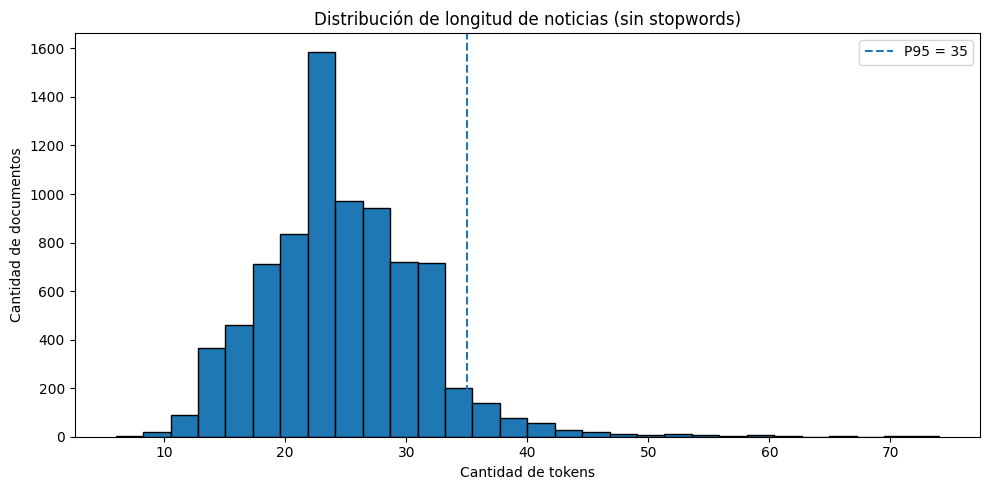

Documentos con longitud <= 35: 95.26%


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Longitud de los textos sin stopwords en train
lengths = train_data["token_length_no_stop"]

# Estadísticas descriptivas
print("ESTADÍSTICAS DE LONGITUD")
print(lengths.describe().round(2))

# Percentil 95, redondeado hacia arriba
p95 = int(np.ceil(lengths.quantile(0.95)))
print("\nPercentil 95:", p95)
print("Max_len recomendado:", p95)

# Histograma
plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=30, edgecolor="black")
plt.axvline(p95, linestyle="--", label=f"P95 = {p95}")
plt.title("Distribución de longitud de noticias (sin stopwords)")
plt.xlabel("Cantidad de tokens")
plt.ylabel("Cantidad de documentos")
plt.legend()
plt.tight_layout()
plt.show()

# Porcentaje de documentos que caben en max_len
porcentaje = (lengths <= p95).mean() * 100
print(f"Documentos con longitud <= {p95}: {porcentaje:.2f}%")

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd

def top_ngrams(texts, ngram_range, top_n=20):
    vectorizer = CountVectorizer(
        ngram_range=ngram_range,
        token_pattern=r"(?u)\b\w+\b"
    )

    matrix = vectorizer.fit_transform(texts)
    frequencies = matrix.sum(axis=0).A1
    terms = vectorizer.get_feature_names_out()

    result = pd.DataFrame({
        "n_grama": terms,
        "frecuencia": frequencies
    })

    return (
        result.sort_values(
            ["frecuencia", "n_grama"],
            ascending=[False, True]
        )
        .head(top_n)
        .reset_index(drop=True)
    )

corpus = train_data["text_lemmas_no_stop"].fillna("")

bigramas = top_ngrams(corpus, (2, 2), 20)
trigramas = top_ngrams(corpus, (3, 3), 20)

print("TOP 20 BIGRAMAS")
display(bigramas)

print("\nTOP 20 TRIGRAMAS")
display(trigramas)

TOP 20 BIGRAMAS


,n_grama,frecuencia
0,ap ap,529
1,u s,503
2,new york,419
3,oil price,197
4,united states,167
5,york reuters,151
6,prime minister,139
7,afp afp,134
8,official say,115
9,reuter reuter,107



TOP 20 TRIGRAMAS


,n_grama,frecuencia
0,new york reuters,151
1,quote profile research,69
2,reuters u s,52
3,n quote profile,40
4,reuter u s,39
5,boston red sox,37
6,u s stock,37
7,york reuters u,36
8,george w bush,28
9,high oil price,27


In [ ]:
from collections import Counter
import pandas as pd

# Contar palabras del corpus lematizado, incluyendo stopwords
word_counter = Counter(
    word
    for text in train_data["text_lemmas"].fillna("")
    for word in text.split()
)

top50 = pd.DataFrame(
    word_counter.most_common(50),
    columns=["palabra", "frecuencia"]
)

# Identificar stopwords según spaCy
stop_words = nlp.Defaults.stop_words

top50["es_stopword"] = top50["palabra"].apply(
    lambda palabra: palabra in stop_words
)

cantidad_stopwords = int(top50["es_stopword"].sum())
porcentaje_stopwords = cantidad_stopwords / len(top50) * 100

print("TOP 50 PALABRAS MÁS FRECUENTES")
display(top50)

print("\nStopwords dentro de las 50 palabras:", cantidad_stopwords)
print(f"Porcentaje de stopwords en el top 50: {porcentaje_stopwords:.2f}%")

TOP 50 PALABRAS MÁS FRECUENTES


,palabra,frecuencia,es_stopword
0,the,13697,True
1,to,7976,True
2,a,7227,True
3,of,6578,True
4,in,6365,True
5,be,5023,True
6,and,4637,True
7,on,3773,True
8,for,3410,True
9,'s,3318,True



Stopwords dentro de las 50 palabras: 38
Porcentaje de stopwords en el top 50: 76.00%


In [ ]:
categorias = ["World", "Sports", "Business", "Sci_Tech"]

print("DISTRIBUCIÓN DEL CORPUS DE ENTRENAMIENTO")
display(
    train_data["label"]
    .value_counts()
    .reindex(categorias)
    .rename_axis("categoría")
    .reset_index(name="cantidad")
)

print("\nDISTRIBUCIÓN DEL CORPUS DE PRUEBA")
display(
    test_data["label"]
    .value_counts()
    .reindex(categorias)
    .rename_axis("categoría")
    .reset_index(name="cantidad")
)

DISTRIBUCIÓN DEL CORPUS DE ENTRENAMIENTO


,categoría,cantidad
0,World,2000
1,Sports,2000
2,Business,2000
3,Sci_Tech,2000



DISTRIBUCIÓN DEL CORPUS DE PRUEBA


,categoría,cantidad
0,World,500
1,Sports,500
2,Business,500
3,Sci_Tech,500


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    Image, PageBreak, KeepTogether
)

# --------------------------------------------------
# 1. Verificaciones
# --------------------------------------------------
assert len(train_data) == 8000, "Revisá train_data: se esperaban 8000 registros."
assert len(test_data) == 2000, "Revisá test_data: se esperaban 2000 registros."
assert {"text_lemmas", "text_lemmas_no_stop", "token_length_no_stop"}.issubset(train_data.columns)
assert len(bigramas) > 0 and len(trigramas) > 0
assert len(top50) == 50

salida = "/content/EDA_NLP_ApellidoNombre.pdf"
carpeta = "/content/eda_nlp_figuras"
os.makedirs(carpeta, exist_ok=True)

# --------------------------------------------------
# 2. Gráficos basados en el corpus real
# --------------------------------------------------
plt.figure(figsize=(8, 4.5))
plt.hist(train_data["token_length_no_stop"].dropna(), bins=25, edgecolor="black")
p95 = int(np.ceil(train_data["token_length_no_stop"].quantile(0.95)))
plt.axvline(p95, linestyle="--", linewidth=2, label=f"Percentil 95 = {p95}")
plt.title("Distribución de tokens por documento")
plt.xlabel("Cantidad de tokens (sin stopwords)")
plt.ylabel("Cantidad de documentos")
plt.legend()
plt.tight_layout()
graf_longitud = f"{carpeta}/longitud.png"
plt.savefig(graf_longitud, dpi=160)
plt.close()

categorias = ["World", "Sports", "Business", "Sci_Tech"]
conteos = train_data["label"].value_counts().reindex(categorias, fill_value=0)

plt.figure(figsize=(8, 4.5))
barras = plt.bar(conteos.index, conteos.values, edgecolor="black")
plt.title("Documentos por categoría — entrenamiento")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de documentos")
plt.bar_label(barras)
plt.tight_layout()
graf_categorias = f"{carpeta}/categorias.png"
plt.savefig(graf_categorias, dpi=160)
plt.close()

# --------------------------------------------------
# 3. Estilos y utilidades para tablas
# --------------------------------------------------
estilos = getSampleStyleSheet()
estilos.add(ParagraphStyle(
    name="Portada", parent=estilos["Title"],
    alignment=TA_CENTER, fontSize=23, leading=29,
    textColor=colors.HexColor("#17365D"), spaceAfter=18
))
estilos.add(ParagraphStyle(
    name="Subtitulo", parent=estilos["Normal"],
    alignment=TA_CENTER, fontSize=11, leading=16,
    textColor=colors.HexColor("#555555")
))
estilos.add(ParagraphStyle(
    name="Seccion", parent=estilos["Heading1"],
    fontSize=16, leading=20, textColor=colors.HexColor("#17365D"),
    spaceBefore=8, spaceAfter=10
))
estilos.add(ParagraphStyle(
    name="Subseccion", parent=estilos["Heading2"],
    fontSize=11, leading=14, textColor=colors.HexColor("#2874A6"),
    spaceBefore=8, spaceAfter=5
))
estilos.add(ParagraphStyle(
    name="CuerpoInforme", parent=estilos["BodyText"],
    fontSize=9, leading=13, spaceAfter=7
))
estilos.add(ParagraphStyle(
    name="TablaPequena", parent=estilos["BodyText"],
    fontSize=7, leading=9
))

def tabla_pdf(df, anchos=None, max_filas=None):
    datos = df.copy()
    if max_filas:
        datos = datos.head(max_filas)
    encabezado = [str(c) for c in datos.columns]
    filas = [encabezado]
    for fila in datos.itertuples(index=False, name=None):
        filas.append([
            str(round(x, 3)) if isinstance(x, (float, np.floating)) else str(x)
            for x in fila
        ])
    t = Table(filas, colWidths=anchos, repeatRows=1, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"),
        ("FONTSIZE", (0, 0), (-1, -1), 7),
        ("LEADING", (0, 0), (-1, -1), 9),
        ("GRID", (0, 0), (-1, -1), 0.35, colors.HexColor("#D5DDE5")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F2F6FA")]),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 4),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
    ]))
    return t

def pie_pagina(canvas, doc):
    canvas.saveState()
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#666666"))
    canvas.drawString(2*cm, 1.1*cm, "EDA de NLP — Corpus AG News")
    canvas.drawRightString(A4[0]-2*cm, 1.1*cm, f"Página {doc.page}")
    canvas.restoreState()

# --------------------------------------------------
# 4. Estadísticas calculadas desde los datos reales
# --------------------------------------------------
n_train = len(train_data)
n_test = len(test_data)
p95_real = int(np.ceil(train_data["token_length_no_stop"].quantile(0.95)))
porcentaje_cobertura = (
    train_data["token_length_no_stop"].le(p95_real).mean() * 100
)
promedio = train_data["token_length_no_stop"].mean()
mediana = train_data["token_length_no_stop"].median()
minimo = train_data["token_length_no_stop"].min()
maximo = train_data["token_length_no_stop"].max()

stop_count = int(top50["es_stopword"].sum())
stop_pct = stop_count / len(top50) * 100

duplicados_train = int(train_df["text"].duplicated().sum())
duplicados_test = int(test_df["text"].duplicated().sum())
cruce = len(
    set(train_df["text"].dropna().astype(str)) &
    set(test_df["text"].dropna().astype(str))
)

# --------------------------------------------------
# 5. Construcción del informe
# --------------------------------------------------
doc = SimpleDocTemplate(
    salida, pagesize=A4,
    rightMargin=1.7*cm, leftMargin=1.7*cm,
    topMargin=1.7*cm, bottomMargin=1.8*cm
)
contenido = []

contenido += [
    Spacer(1, 3*cm),
    Paragraph("ANÁLISIS EXPLORATORIO DE DATOS", estilos["Portada"]),
    Paragraph("Procesamiento y preparación de un corpus para modelado NLP",
              estilos["Subtitulo"]),
    Spacer(1, 1.5*cm),
    Paragraph("<b>Dataset:</b> AG News", estilos["CuerpoInforme"]),
    Paragraph("<b>Herramientas:</b> Python, pandas, spaCy y scikit-learn",
              estilos["CuerpoInforme"]),
    Paragraph("<b>Objetivo:</b> inspeccionar, limpiar y caracterizar el corpus "
              "antes de utilizarlo en tareas de procesamiento de lenguaje natural.",
              estilos["CuerpoInforme"]),
    Spacer(1, 2*cm),
    Paragraph("Informe generado a partir de los resultados reales obtenidos en Colab.",
              estilos["Subtitulo"]),
    PageBreak()
]

contenido += [
    Paragraph("1. Descripción y control de calidad", estilos["Seccion"]),
    Paragraph(
        f"El conjunto de entrenamiento contiene <b>{n_train:,}</b> documentos "
        f"y el de prueba <b>{n_test:,}</b>. Ambos mantienen cuatro categorías: "
        "World, Sports, Business y Sci_Tech. Se conservaron separados para "
        "evitar utilizar el conjunto de prueba como fuente de entrenamiento.",
        estilos["CuerpoInforme"]
    ),
    tabla_pdf(pd.DataFrame({
        "Conjunto": ["Entrenamiento", "Prueba"],
        "Documentos": [n_train, n_test],
        "Nulos en texto": [
            int(train_df["text"].isna().sum()),
            int(test_df["text"].isna().sum())
        ],
        "Duplicados exactos": [duplicados_train, duplicados_test]
    }), anchos=[4*cm, 3*cm, 3.5*cm, 4*cm]),
    Spacer(1, 8),
    Paragraph(
        f"Coincidencias exactas de texto entre entrenamiento y prueba: "
        f"<b>{cruce}</b>. La distribución de etiquetas está equilibrada: "
        "2.000 documentos por categoría en entrenamiento y 500 por categoría "
        "en prueba.",
        estilos["CuerpoInforme"]
    ),
    Image(graf_categorias, width=15.5*cm, height=8.7*cm),
    Paragraph("2. Limpieza y lematización", estilos["Seccion"]),
    Paragraph(
        "El preprocesamiento normaliza el texto a minúsculas, decodifica "
        "entidades HTML, elimina etiquetas, URLs y correos electrónicos, "
        "limpia caracteres no relevantes y normaliza espacios. Luego, spaCy "
        "se utiliza para tokenizar y obtener lemas. Se generaron versiones "
        "lematizadas con y sin stopwords. Los números se conservaron porque "
        "pueden aportar información relevante en noticias.",
        estilos["CuerpoInforme"]
    ),
    PageBreak()
]

contenido += [
    Paragraph("3. Longitud de los documentos", estilos["Seccion"]),
    Paragraph(
        f"La longitud se calculó sobre los textos lematizados sin stopwords. "
        f"El promedio es {promedio:.2f} tokens, la mediana {mediana:.0f}, "
        f"el mínimo {minimo:.0f} y el máximo {maximo:.0f}. "
        f"El percentil 95, redondeado hacia arriba, es {p95_real} tokens. "
        f"Con ese umbral, el {porcentaje_cobertura:.2f}% de los documentos "
        "queda dentro de la longitud seleccionada.",
        estilos["CuerpoInforme"]
    ),
    Image(graf_longitud, width=15.5*cm, height=8.7*cm),
    Paragraph(
        f"Recomendación inicial: utilizar <b>max_len = {p95_real}</b> en una "
        "primera configuración de modelado. Esto limita la longitud de las "
        "secuencias y cubre aproximadamente el 95% de los documentos; el resto "
        "puede requerir truncamiento. La elección debe validarse en etapas "
        "posteriores según el modelo y su desempeño.",
        estilos["CuerpoInforme"]
    ),
    Paragraph("4. Palabras más frecuentes y stopwords", estilos["Seccion"]),
    Paragraph(
        f"De las 50 palabras más frecuentes del corpus lematizado, "
        f"{stop_count} ({stop_pct:.2f}%) están identificadas como stopwords "
        "por spaCy. La elevada presencia de palabras funcionales en el ranking "
        "justifica analizar también una versión sin stopwords. Entre los términos "
        "no clasificados como stopwords aparecen palabras temáticas como "
        "company, world, win y game, junto con términos editoriales o de agencias "
        "como ap, reuters y quot.",
        estilos["CuerpoInforme"]
    ),
    tabla_pdf(top50[["palabra", "frecuencia", "es_stopword"]].astype(str),
              anchos=[5*cm, 4*cm, 4*cm]),
    PageBreak()
]

contenido += [
    Paragraph("5. Bigramas y trigramas", estilos["Seccion"]),
    Paragraph(
        "Los n-gramas se calcularon sobre el corpus de entrenamiento lematizado "
        "sin stopwords. Los bigramas permiten identificar asociaciones de dos "
        "términos y los trigramas expresiones de tres términos. Entre los "
        "resultados aparecen combinaciones temáticas como “new york”, “oil price” "
        "y “prime minister”. También se observan créditos de agencias y residuos "
        "editoriales, como “ap ap”, “afp afp” y “quote profile research”. "
        "Estos patrones sugieren que podría evaluarse una limpieza específica "
        "de metadatos en una iteración futura, documentando los cambios y "
        "sin modificar retrospectivamente los resultados reportados.",
        estilos["CuerpoInforme"]
    ),
    Paragraph("Top 20 bigramas", estilos["Subseccion"]),
    tabla_pdf(bigramas[["n_grama", "frecuencia"]], anchos=[10*cm, 3*cm]),
    Spacer(1, 10),
    Paragraph("Top 20 trigramas", estilos["Subseccion"]),
    tabla_pdf(trigramas[["n_grama", "frecuencia"]], anchos=[10*cm, 3*cm]),
    PageBreak()
]

conclusion = (
    "El análisis exploratorio permitió verificar que AG News contiene 8.000 "
    "documentos de entrenamiento y 2.000 de prueba, distribuidos de forma "
    "equilibrada entre cuatro categorías. No se detectaron valores nulos ni "
    "duplicados exactos dentro de los conjuntos analizados, y no hubo textos "
    "idénticos compartidos entre entrenamiento y prueba. El preprocesamiento "
    "generó representaciones limpias y lematizadas, con y sin stopwords, "
    "manteniendo números potencialmente informativos. La longitud de los "
    f"documentos sin stopwords presenta una mediana de {mediana:.0f} tokens; "
    f"el percentil 95 redondeado es {p95_real}, por lo que se propone "
    f"max_len={p95_real} como punto de partida. Además, el 76% de las 50 "
    "palabras más frecuentes se identificó como stopwords, mientras que los "
    "n-gramas mostraron tanto expresiones temáticas como restos de créditos "
    "editoriales. En consecuencia, el corpus está preparado para continuar "
    "hacia el modelado, manteniendo separados entrenamiento y prueba. Como "
    "mejora futura, conviene evaluar la eliminación selectiva de metadatos "
    "y comprobar su efecto antes de fijar la configuración definitiva."
)

contenido += [
    Paragraph("6. Conclusiones", estilos["Seccion"]),
    Paragraph(conclusion, estilos["CuerpoInforme"]),
    Spacer(1, 10),
    Paragraph(
        "<b>Nota metodológica:</b> las métricas y tablas de este informe se "
        "calculan a partir de las variables existentes en la sesión de Colab. "
        "La conclusión describe hallazgos exploratorios y no presupone resultados "
        "de entrenamiento o evaluación de modelos.",
        estilos["CuerpoInforme"]
    )
]

doc.build(contenido, onFirstPage=pie_pagina, onLaterPages=pie_pagina)

print("PDF generado correctamente:", salida)
print("Tamaño del archivo:", round(os.path.getsize(salida) / 1024, 1), "KB")

from google.colab import files
files.download(salida)


PDF generado correctamente: /content/EDA_NLP_ApellidoNombre.pdf
Tamaño del archivo: 115.8 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Verificar que los resultados del análisis sigan disponibles
variables_necesarias = [
    "train_data",
    "test_data",
    "top50",
    "bigramas",
    "trigramas"
]

for variable in variables_necesarias:
    disponible = variable in globals()
    print(f"{variable}: {'OK' if disponible else 'FALTA'}")

if all(variable in globals() for variable in variables_necesarias):
    print("\nTodo listo. Podemos corregir el PDF sin repetir el análisis.")
else:
    print("\nFalta alguna variable. No cierres ni reinicies el notebook.")


train_data: OK
test_data: OK
top50: OK
bigramas: OK
trigramas: OK

Todo listo. Podemos corregir el PDF sin repetir el análisis.


In [ ]:

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    Image, PageBreak, KeepTogether
)
from google.colab import files

# ------------------------------------------------
# CONFIGURACIÓN
# ------------------------------------------------
salida = "/content/EDA_NLP_ApellidoNombre_CORREGIDO.pdf"
carpeta = "/content/eda_nlp_figuras_corregidas"
os.makedirs(carpeta, exist_ok=True)

AZUL = colors.HexColor("#17365D")
CELESTE = colors.HexColor("#DCE6F1")
GRIS = colors.HexColor("#F3F5F7")
TEXTO = colors.HexColor("#263238")

# ------------------------------------------------
# ESTADÍSTICAS REALES
# ------------------------------------------------
categorias = ["World", "Sports", "Business", "Sci_Tech"]
conteos_train = train_data["label"].value_counts().reindex(categorias, fill_value=0)
conteos_test = test_data["label"].value_counts().reindex(categorias, fill_value=0)

longitudes = train_data["token_length_no_stop"].dropna()
p95 = int(np.ceil(longitudes.quantile(0.95)))
cobertura = longitudes.le(p95).mean() * 100
promedio = longitudes.mean()
mediana = longitudes.median()
minimo = longitudes.min()
maximo = longitudes.max()

stop_count = int(top50["es_stopword"].sum())
stop_pct = stop_count / len(top50) * 100

cruce = len(
    set(train_data["text"].dropna().astype(str)) &
    set(test_data["text"].dropna().astype(str))
)

# ------------------------------------------------
# GRÁFICOS
# ------------------------------------------------
plt.figure(figsize=(8, 4))
plt.hist(longitudes, bins=25, edgecolor="black")
plt.axvline(p95, linestyle="--", linewidth=2, label=f"P95 = {p95}")
plt.title("Distribución de tokens por documento")
plt.xlabel("Tokens por documento (sin stopwords)")
plt.ylabel("Cantidad de documentos")
plt.legend()
plt.tight_layout()
graf_longitud = f"{carpeta}/longitud.png"
plt.savefig(graf_longitud, dpi=180, bbox_inches="tight")
plt.close()

plt.figure(figsize=(8, 4))
barras = plt.bar(conteos_train.index, conteos_train.values, edgecolor="black")
plt.title("Documentos por categoría — entrenamiento")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de documentos")
plt.bar_label(barras)
plt.tight_layout()
graf_categorias = f"{carpeta}/categorias.png"
plt.savefig(graf_categorias, dpi=180, bbox_inches="tight")
plt.close()

# ------------------------------------------------
# ESTILOS
# ------------------------------------------------
styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="PortadaNueva", parent=styles["Title"],
    fontName="Helvetica-Bold", fontSize=23, leading=29,
    alignment=TA_CENTER, textColor=AZUL, spaceAfter=18
))
styles.add(ParagraphStyle(
    name="SubPortada", parent=styles["Normal"],
    fontSize=11, leading=16, alignment=TA_CENTER,
    textColor=colors.HexColor("#555555")
))
styles.add(ParagraphStyle(
    name="H1Nuevo", parent=styles["Heading1"],
    fontSize=15, leading=19, textColor=AZUL,
    spaceBefore=4, spaceAfter=9
))
styles.add(ParagraphStyle(
    name="H2Nuevo", parent=styles["Heading2"],
    fontSize=10, leading=13, textColor=AZUL,
    spaceBefore=5, spaceAfter=5
))
styles.add(ParagraphStyle(
    name="TextoNuevo", parent=styles["BodyText"],
    fontSize=8.8, leading=12, textColor=TEXTO, spaceAfter=7
))
styles.add(ParagraphStyle(
    name="Celda", parent=styles["BodyText"],
    fontSize=7.2, leading=9
))
styles.add(ParagraphStyle(
    name="CeldaCentro", parent=styles["BodyText"],
    fontSize=7.2, leading=9, alignment=TA_CENTER
))

def tabla_estilizada(df, anchos, font_size=7.2):
    # Convertir las celdas en párrafos para que el texto pueda ajustarse.
    encabezados = [
        Paragraph(f"<b>{str(c)}</b>", styles["Celda"])
        for c in df.columns
    ]
    filas = [encabezados]

    for fila in df.itertuples(index=False, name=None):
        celdas = []
        for valor in fila:
            if pd.isna(valor):
                valor = ""
            if isinstance(valor, (float, np.floating)):
                valor = f"{valor:.2f}" if not float(valor).is_integer() else str(int(valor))
            celdas.append(Paragraph(str(valor), styles["Celda"]))
        filas.append(celdas)

    tabla = Table(
        filas, colWidths=anchos, repeatRows=1,
        hAlign="LEFT", splitByRow=1
    )
    tabla.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), AZUL),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.35, colors.HexColor("#CFD8E3")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1), [colors.white, GRIS]),
        ("VALIGN", (0, 0), (-1, -1), "TOP"),
        ("LEFTPADDING", (0, 0), (-1, -1), 5),
        ("RIGHTPADDING", (0, 0), (-1, -1), 5),
        ("TOPPADDING", (0, 0), (-1, -1), 4),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 4),
    ]))
    return tabla

def pie(canvas, doc):
    canvas.saveState()
    ancho, alto = doc.pagesize
    canvas.setStrokeColor(colors.HexColor("#D5DDE5"))
    canvas.line(1.7*cm, 1.45*cm, ancho-1.7*cm, 1.45*cm)
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(colors.HexColor("#59636E"))
    canvas.drawString(1.7*cm, 0.95*cm, "EDA de NLP | Corpus AG News")
    canvas.drawRightString(ancho-1.7*cm, 0.95*cm, f"Página {doc.page}")
    canvas.restoreState()

# ------------------------------------------------
# DOCUMENTO
# ------------------------------------------------
doc = SimpleDocTemplate(
    salida, pagesize=A4,
    rightMargin=1.7*cm, leftMargin=1.7*cm,
    topMargin=1.7*cm, bottomMargin=1.9*cm,
    title="Análisis exploratorio de datos — AG News",
    author="Informe académico de NLP"
)
story = []

# PORTADA
story += [
    Spacer(1, 3.0*cm),
    Paragraph("ANÁLISIS EXPLORATORIO<br/>DE DATOS", styles["PortadaNueva"]),
    Paragraph("Procesamiento y preparación de un corpus para modelado NLP",
              styles["SubPortada"]),
    Spacer(1, 1.6*cm),
    Paragraph("<b>Dataset:</b> AG News", styles["TextoNuevo"]),
    Paragraph("<b>Herramientas:</b> Python, pandas, spaCy y scikit-learn",
              styles["TextoNuevo"]),
    Paragraph("<b>Objetivo:</b> inspeccionar, limpiar y caracterizar el corpus "
              "antes de utilizarlo en tareas de procesamiento de lenguaje natural.",
              styles["TextoNuevo"]),
    Spacer(1, 1.6*cm),
    Paragraph("Informe elaborado a partir de los resultados obtenidos en Google Colab.",
              styles["SubPortada"]),
    PageBreak()
]

# 1. CALIDAD DEL CORPUS
story += [
    Paragraph("1. Descripción y control de calidad", styles["H1Nuevo"]),
    Paragraph(
        f"El corpus contiene <b>{len(train_data):,}</b> documentos de entrenamiento "
        f"y <b>{len(test_data):,}</b> de prueba. Se mantuvieron separados para "
        "evitar utilizar el conjunto de prueba durante el entrenamiento.",
        styles["TextoNuevo"]
    )
]

calidad = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Documentos": [len(train_data), len(test_data)],
    "Textos nulos": [
        int(train_data["text"].isna().sum()),
        int(test_data["text"].isna().sum())
    ],
    "Duplicados exactos": [
        int(train_data["text"].duplicated().sum()),
        int(test_data["text"].duplicated().sum())
    ]
})
story += [
    tabla_estilizada(calidad, [4.0*cm, 3.0*cm, 3.0*cm, 4.0*cm]),
    Spacer(1, 8),
    Paragraph(
        f"No se detectaron textos idénticos compartidos entre ambos conjuntos "
        f"(coincidencias: <b>{cruce}</b>). La distribución está equilibrada: "
        "2.000 documentos por categoría en entrenamiento y 500 por categoría "
        "en prueba.",
        styles["TextoNuevo"]
    ),
    Image(graf_categorias, width=15.5*cm, height=7.75*cm),
    Paragraph("2. Limpieza y lematización", styles["H1Nuevo"]),
    Paragraph(
        "El preprocesamiento normaliza el texto a minúsculas, decodifica "
        "entidades HTML, elimina etiquetas, URLs y correos electrónicos, "
        "limpia caracteres no relevantes y normaliza espacios. Luego, spaCy "
        "se utiliza para tokenizar y obtener lemas. Se generaron versiones "
        "lematizadas con y sin stopwords. Los números se conservaron porque "
        "pueden aportar información relevante en noticias.",
        styles["TextoNuevo"]
    ),
    PageBreak()
]

# 3. LONGITUD
story += [
    Paragraph("3. Longitud de los documentos", styles["H1Nuevo"]),
    Paragraph(
        f"La longitud se calculó sobre los textos lematizados sin stopwords. "
        f"El promedio es <b>{promedio:.2f}</b> tokens, la mediana <b>{mediana:.0f}</b>, "
        f"el mínimo <b>{minimo:.0f}</b> y el máximo <b>{maximo:.0f}</b>. "
        f"El percentil 95 redondeado hacia arriba es <b>{p95}</b> tokens. "
        f"El <b>{cobertura:.2f}%</b> de los documentos tiene una longitud igual "
        "o inferior a ese umbral.",
        styles["TextoNuevo"]
    ),
    Image(graf_longitud, width=15.5*cm, height=7.75*cm),
    Paragraph(
        f"Se recomienda probar <b>max_len = {p95}</b> como configuración inicial. "
        "Esta longitud cubre aproximadamente el 95% de los documentos, aunque "
        "una pequeña proporción puede requerir truncamiento. La elección debe "
        "validarse en etapas posteriores según el modelo y su desempeño.",
        styles["TextoNuevo"]
    ),
    Paragraph("4. Palabras más frecuentes y stopwords", styles["H1Nuevo"]),
    Paragraph(
        f"De las 50 palabras más frecuentes del corpus lematizado, "
        f"<b>{stop_count} ({stop_pct:.2f}%)</b> están identificadas como stopwords "
        "por spaCy. Entre los términos no clasificados como stopwords aparecen "
        "palabras temáticas como company, world, win y game, junto con términos "
        "editoriales o de agencias como ap, reuters y quot.",
        styles["TextoNuevo"]
    ),
    Paragraph(
        "La tabla completa se presenta en la página siguiente para mantener "
        "la legibilidad y evitar que las filas se dividan entre páginas.",
        styles["TextoNuevo"]
    ),
    PageBreak()
]

# TABLA TOP 50 EN PÁGINA PROPIA
top50_pdf = top50[["palabra", "frecuencia", "es_stopword"]].copy()
top50_pdf["es_stopword"] = top50_pdf["es_stopword"].map(
    {True: "Sí", False: "No"}
)

story += [
    Paragraph("Tabla 1. Top 50 palabras más frecuentes", styles["H1Nuevo"]),
    Paragraph(
        "Las stopwords se identifican según la lista predeterminada de spaCy. "
        "La frecuencia corresponde al corpus de entrenamiento lematizado.",
        styles["TextoNuevo"]
    ),
    tabla_estilizada(
        top50_pdf,
        [5.0*cm, 4.0*cm, 4.0*cm]
    ),
    PageBreak()
]

# 5. BIGRAMAS Y TRIGRAMAS EN PÁGINAS SEPARADAS
story += [
    Paragraph("5. Bigramas", styles["H1Nuevo"]),
    Paragraph(
        "Los bigramas reflejan asociaciones de dos términos. Aparecen "
        "combinaciones temáticas como “new york”, “oil price” y “prime minister”, "
        "junto con créditos de agencias y residuos editoriales como “ap ap” "
        "y “afp afp”.",
        styles["TextoNuevo"]
    ),
    tabla_estilizada(
        bigramas[["n_grama", "frecuencia"]].reset_index(drop=True),
        [10.0*cm, 3.0*cm]
    ),
    PageBreak(),
    Paragraph("6. Trigramas", styles["H1Nuevo"]),
    Paragraph(
        "Los trigramas permiten observar expresiones más largas. Entre los "
        "resultados aparecen nombres propios y expresiones temáticas, pero "
        "también fragmentos de créditos y metadatos, como “quote profile research”. "
        "Esto sugiere evaluar una limpieza selectiva de metadatos en una futura "
        "iteración, documentando cualquier cambio.",
        styles["TextoNuevo"]
    ),
    tabla_estilizada(
        trigramas[["n_grama", "frecuencia"]].reset_index(drop=True),
        [10.0*cm, 3.0*cm]
    ),
    PageBreak()
]

# CONCLUSIÓN <= 300 PALABRAS
conclusion = (
    "El análisis exploratorio permitió verificar que AG News contiene 8.000 "
    "documentos de entrenamiento y 2.000 de prueba, distribuidos de forma "
    "equilibrada entre cuatro categorías. No se detectaron valores nulos ni "
    "duplicados exactos dentro de los conjuntos analizados, y no hubo textos "
    "idénticos compartidos entre entrenamiento y prueba. El preprocesamiento "
    "generó representaciones limpias y lematizadas, con y sin stopwords, "
    "manteniendo números potencialmente informativos. La longitud de los "
    f"documentos sin stopwords presenta una mediana de {mediana:.0f} tokens; "
    f"el percentil 95 redondeado es {p95}, por lo que se propone max_len={p95} "
    "como punto de partida. Además, el 76% de las 50 palabras más frecuentes "
    "se identificó como stopwords, mientras que los n-gramas mostraron tanto "
    "expresiones temáticas como restos de créditos editoriales. En consecuencia, "
    "el corpus está preparado para continuar hacia el modelado, manteniendo "
    "separados entrenamiento y prueba. Como mejora futura, conviene evaluar "
    "la eliminación selectiva de metadatos y comprobar su efecto antes de fijar "
    "la configuración definitiva."
)

story += [
    Paragraph("7. Conclusiones", styles["H1Nuevo"]),
    Paragraph(conclusion, styles["TextoNuevo"]),
    Spacer(1, 8),
    Paragraph(
        "<b>Nota metodológica:</b> los resultados presentados se calculan a "
        "partir de las variables generadas durante el análisis exploratorio. "
        "Este informe no presupone resultados de entrenamiento o evaluación "
        "de modelos.",
        styles["TextoNuevo"]
    )
]

doc.build(story, onFirstPage=pie, onLaterPages=pie)

print("PDF corregido generado:", salida)
print("Tamaño:", round(os.path.getsize(salida)/1024, 1), "KB")
print("Palabras de la conclusión:", len(conclusion.split()))

files.download(salida)


PDF corregido generado: /content/EDA_NLP_ApellidoNombre_CORREGIDO.pdf
Tamaño: 131.7 KB
Palabras de la conclusión: 153


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib import colors
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle, PageBreak
)
from reportlab.lib.enums import TA_CENTER
from google.colab import files
import os

archivo_prueba = "/content/EDA_NLP_Tablas_Corregidas.pdf"
est = getSampleStyleSheet()
est.add(ParagraphStyle(
    name="TituloTabla", parent=est["Title"],
    fontSize=17, leading=21, alignment=TA_CENTER,
    textColor=colors.HexColor("#17365D")
))
est.add(ParagraphStyle(
    name="CeldaTabla", parent=est["BodyText"],
    fontSize=9, leading=11
))

def crear_tabla(df, anchos):
    filas = [[
        Paragraph(f"<b>{str(col)}</b>", est["CeldaTabla"])
        for col in df.columns
    ]]
    for fila in df.itertuples(index=False, name=None):
        filas.append([
            Paragraph(str(valor), est["CeldaTabla"])
            for valor in fila
        ])

    tabla = Table(filas, colWidths=anchos, repeatRows=1)
    tabla.setStyle(TableStyle([
        ("BACKGROUND", (0, 0), (-1, 0), colors.HexColor("#17365D")),
        ("TEXTCOLOR", (0, 0), (-1, 0), colors.white),
        ("GRID", (0, 0), (-1, -1), 0.5, colors.HexColor("#CCD5DF")),
        ("ROWBACKGROUNDS", (0, 1), (-1, -1),
         [colors.white, colors.HexColor("#F1F5F9")]),
        ("VALIGN", (0, 0), (-1, -1), "MIDDLE"),
        ("LEFTPADDING", (0, 0), (-1, -1), 7),
        ("RIGHTPADDING", (0, 0), (-1, -1), 7),
        ("TOPPADDING", (0, 0), (-1, -1), 5),
        ("BOTTOMPADDING", (0, 0), (-1, -1), 5),
    ]))
    return tabla

doc = SimpleDocTemplate(
    archivo_prueba,
    pagesize=landscape(A4),
    rightMargin=1.5*cm,
    leftMargin=1.5*cm,
    topMargin=1.5*cm,
    bottomMargin=1.5*cm
)

story = []

# Top 50: tabla completa y legible
top = top50[["palabra", "frecuencia", "es_stopword"]].copy()
top["es_stopword"] = top["es_stopword"].map({True: "Sí", False: "No"})

story += [
    Paragraph("Top 50 palabras más frecuentes", est["TituloTabla"]),
    Spacer(1, 12),
    crear_tabla(top, [8*cm, 5*cm, 5*cm]),
    PageBreak()
]

# Bigramas
story += [
    Paragraph("Top 20 bigramas", est["TituloTabla"]),
    Spacer(1, 12),
    crear_tabla(
        bigramas[["n_grama", "frecuencia"]].reset_index(drop=True),
        [15*cm, 5*cm]
    ),
    PageBreak()
]

# Trigramas
story += [
    Paragraph("Top 20 trigramas", est["TituloTabla"]),
    Spacer(1, 12),
    crear_tabla(
        trigramas[["n_grama", "frecuencia"]].reset_index(drop=True),
        [15*cm, 5*cm]
    )
]

doc.build(story)

print("Archivo generado:", archivo_prueba)
print("Tamaño:", round(os.path.getsize(archivo_prueba)/1024, 1), "KB")
files.download(archivo_prueba)


Archivo generado: /content/EDA_NLP_Tablas_Corregidas.pdf
Tamaño: 8.0 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# INFORME FINAL EDA - AG NEWS
# Genera: EDA_NLP_ApellidoNombre.pdf
# Requiere las variables ya creadas en el notebook:
# train_data, test_data, top50, bigramas, trigramas
# ============================================================

!pip -q install reportlab matplotlib

import os, math, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from reportlab.lib import colors
from reportlab.lib.enums import TA_CENTER, TA_LEFT
from reportlab.lib.pagesizes import A4, landscape
from reportlab.lib.styles import getSampleStyleSheet, ParagraphStyle
from reportlab.lib.units import cm
from reportlab.platypus import (
    SimpleDocTemplate, Paragraph, Spacer, Table, TableStyle,
    PageBreak, Image, KeepTogether
)
from google.colab import files

OUT = "/content/EDA_NLP_ApellidoNombre.pdf"

# ---------- Utilidades ----------
def find_col(df, options):
    for c in options:
        if c in df.columns:
            return c
    return None

label_col = find_col(train_data, ["label", "category", "class"])
text_col = find_col(train_data, ["text", "news", "content"])
length_col = find_col(train_data, ["token_length_no_stop", "token_length"])

if label_col is None or text_col is None:
    raise ValueError("No se encuentran las columnas de categoría y texto en train_data.")

if length_col is None:
    # Respaldo si la columna de longitud no existe
    train_data["token_length_no_stop"] = train_data[text_col].fillna("").astype(str).str.split().str.len()
    length_col = "token_length_no_stop"

# ---------- Estilo ----------
NAVY = colors.HexColor("#17365D")
BLUE = colors.HexColor("#2878B5")
LIGHT = colors.HexColor("#EAF1F8")
MID = colors.HexColor("#D5E2F0")
DARK = colors.HexColor("#263238")
GRAY = colors.HexColor("#5B6573")

styles = getSampleStyleSheet()
styles.add(ParagraphStyle(
    name="CoverTitle", parent=styles["Title"], fontName="Helvetica-Bold",
    fontSize=25, leading=31, textColor=NAVY, alignment=TA_CENTER,
    spaceAfter=18
))
styles.add(ParagraphStyle(
    name="SubTitleCustom", parent=styles["Normal"], fontSize=12,
    leading=18, textColor=GRAY, alignment=TA_CENTER
))
styles.add(ParagraphStyle(
    name="H1Custom", parent=styles["Heading1"], fontName="Helvetica-Bold",
    fontSize=16, leading=20, textColor=NAVY, spaceBefore=8, spaceAfter=9
))
styles.add(ParagraphStyle(
    name="H2Custom", parent=styles["Heading2"], fontName="Helvetica-Bold",
    fontSize=11, leading=14, textColor=BLUE, spaceBefore=6, spaceAfter=5
))
styles.add(ParagraphStyle(
    name="BodyCustom", parent=styles["BodyText"], fontSize=9.2,
    leading=14, textColor=DARK, spaceAfter=7
))
styles.add(ParagraphStyle(
    name="SmallCustom", parent=styles["BodyText"], fontSize=7.5,
    leading=9.5, textColor=DARK
))
styles.add(ParagraphStyle(
    name="TableHeadCustom", parent=styles["BodyText"], fontSize=7.5,
    leading=9, textColor=colors.white, alignment=TA_LEFT
))

def P(txt, style="BodyCustom"):
    return Paragraph(str(txt), styles[style])

def make_table(data, widths=None, font=8, repeat=1):
    t = Table(data, colWidths=widths, repeatRows=repeat, hAlign="LEFT")
    t.setStyle(TableStyle([
        ("BACKGROUND", (0,0), (-1,0), NAVY),
        ("TEXTCOLOR", (0,0), (-1,0), colors.white),
        ("FONTNAME", (0,0), (-1,0), "Helvetica-Bold"),
        ("FONTNAME", (0,1), (-1,-1), "Helvetica"),
        ("FONTSIZE", (0,0), (-1,-1), font),
        ("LEADING", (0,0), (-1,-1), font+2),
        ("GRID", (0,0), (-1,-1), 0.35, colors.HexColor("#C9D3DF")),
        ("ROWBACKGROUNDS", (0,1), (-1,-1), [colors.white, LIGHT]),
        ("VALIGN", (0,0), (-1,-1), "MIDDLE"),
        ("LEFTPADDING", (0,0), (-1,-1), 5),
        ("RIGHTPADDING", (0,0), (-1,-1), 5),
        ("TOPPADDING", (0,0), (-1,-1), 4),
        ("BOTTOMPADDING", (0,0), (-1,-1), 4),
    ]))
    return t

def footer(canvas, doc):
    canvas.saveState()
    w, h = doc.pagesize
    canvas.setStrokeColor(MID)
    canvas.line(1.7*cm, 1.35*cm, w-1.7*cm, 1.35*cm)
    canvas.setFont("Helvetica", 8)
    canvas.setFillColor(GRAY)
    canvas.drawString(1.7*cm, 0.9*cm, "EDA de NLP | AG News | Corpus preprocesado")
    canvas.drawRightString(w-1.7*cm, 0.9*cm, f"Página {doc.page}")
    canvas.restoreState()

# ---------- Estadísticas calculadas desde los datos ----------
n_train, n_test = len(train_data), len(test_data)
dist_train = train_data[label_col].value_counts().sort_index()
dist_test = test_data[label_col].value_counts().sort_index()

lengths = pd.to_numeric(train_data[length_col], errors="coerce").dropna()
mean_len = lengths.mean()
std_len = lengths.std()
min_len = lengths.min()
med_len = lengths.median()
q1, q3 = lengths.quantile([.25, .75])
p95 = math.ceil(lengths.quantile(.95))
max_len = lengths.max()
pct_35 = (lengths <= 35).mean() * 100

null_train = int(train_data[[label_col, text_col]].isna().any(axis=1).sum())
null_test = int(test_data[[label_col, text_col]].isna().any(axis=1).sum())
dup_train = int(train_data[text_col].duplicated().sum())
dup_test = int(test_data[text_col].duplicated().sum())
cross_duplicates = len(set(train_data[text_col].dropna()) & set(test_data[text_col].dropna()))

# ---------- Gráficos ----------
plot_paths = []

# Distribución de categorías
fig, ax = plt.subplots(figsize=(8, 4.2))
cats = list(dist_train.index.astype(str))
vals = list(dist_train.values)
ax.bar(cats, vals)
ax.set_title("Distribución de categorías — entrenamiento")
ax.set_ylabel("Cantidad de documentos")
ax.set_xlabel("Categoría")
ax.grid(axis="y", alpha=.25)
fig.tight_layout()
p = "/content/eda_categorias.png"
fig.savefig(p, dpi=180, bbox_inches="tight")
plt.close(fig)
plot_paths.append(p)

# Longitud de documentos
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(lengths, bins=22, edgecolor="white")
ax.axvline(p95, linestyle="--", linewidth=2, label=f"Percentil 95 redondeado: {p95}")
ax.set_title("Longitud de documentos sin stopwords")
ax.set_xlabel("Tokens por documento")
ax.set_ylabel("Frecuencia")
ax.legend()
ax.grid(axis="y", alpha=.2)
fig.tight_layout()
p = "/content/eda_longitudes.png"
fig.savefig(p, dpi=180, bbox_inches="tight")
plt.close(fig)
plot_paths.append(p)

# ---------- Tabla top 50: dos bloques lado a lado para evitar cortes ----------
top_df = top50.copy() if isinstance(top50, pd.DataFrame) else pd.DataFrame(top50)
top_df.columns = [str(c).strip() for c in top_df.columns]

word_col = find_col(top_df, ["palabra", "word", "token", "term"])
freq_col = find_col(top_df, ["frecuencia", "frequency", "count", "freq"])
stop_col = find_col(top_df, ["es_stopword", "stopword", "is_stopword"])

if word_col is None: word_col = top_df.columns[0]
if freq_col is None: freq_col = top_df.columns[1]
if stop_col is None and len(top_df.columns) >= 3: stop_col = top_df.columns[2]

top_df = top_df.head(50).copy()
if stop_col:
    top_df[stop_col] = top_df[stop_col].map(
        lambda x: "Sí" if str(x).lower() in ["true","1","sí","si","yes"] else
        ("No" if str(x).lower() in ["false","0","no"] else str(x))
    )

def prepare_ngram_df(df):
    x = df.copy() if isinstance(df, pd.DataFrame) else pd.DataFrame(df)
    x.columns = [str(c).strip() for c in x.columns]
    return x

bi_df = prepare_ngram_df(bigramas).head(20)
tri_df = prepare_ngram_df(trigramas).head(20)

def ngram_rows(df):
    # Si la tabla ya tiene columnas de expresión y frecuencia, conservarlas.
    if len(df.columns) >= 2:
        return [[str(df.columns[0]), str(df.columns[1])]] + [
            [str(a), str(b)] for a,b in df.iloc[:, :2].itertuples(index=False, name=None)
        ]
    return [["Expresión", "Frecuencia"]] + [[str(i), str(v)] for i,v in df.iloc[:,0].items()]

# ---------- Documento ----------
doc = SimpleDocTemplate(
    OUT, pagesize=landscape(A4),
    rightMargin=1.7*cm, leftMargin=1.7*cm,
    topMargin=1.6*cm, bottomMargin=1.7*cm
)
story = []

# Portada
story += [
    Spacer(1, 2.1*cm),
    P("ANÁLISIS EXPLORATORIO DE DATOS<br/>PARA PROCESAMIENTO DE LENGUAJE NATURAL", "CoverTitle"),
    P("AG News · Corpus preprocesado listo para modelado", "SubTitleCustom"),
    Spacer(1, 1.2*cm),
]
summary_data = [
    ["Indicador", "Resultado"],
    ["Documentos de entrenamiento", f"{n_train:,}".replace(",", ".")],
    ["Documentos de prueba", f"{n_test:,}".replace(",", ".")],
    ["Categorías", str(train_data[label_col].nunique())],
    ["Longitud recomendada inicial", f"max_len = {p95} tokens"],
]
story += [make_table(summary_data, [8*cm, 8*cm], font=10), Spacer(1, 1.0*cm)]
story += [
    P("Objetivo", "H2Custom"),
    P("Evaluar la estructura, calidad, distribución y características lingüísticas del corpus antes de iniciar el modelado, documentando hallazgos relevantes y decisiones de preprocesamiento."),
    PageBreak()
]

# 1. Dataset y calidad
story += [
    P("1. Descripción y calidad del corpus", "H1Custom"),
    P("AG News se utiliza para una tarea de clasificación de noticias. El conjunto analizado contiene un subconjunto de entrenamiento y otro de prueba, con la variable de categoría y el texto de cada noticia."),
]
quality = [
    ["Control", "Entrenamiento", "Prueba"],
    ["Cantidad de documentos", str(n_train), str(n_test)],
    ["Filas con nulos en categoría/texto", str(null_train), str(null_test)],
    ["Textos duplicados exactos dentro del conjunto", str(dup_train), str(dup_test)],
    ["Textos idénticos compartidos entre ambos conjuntos", str(cross_duplicates), "—"],
]
story += [make_table(quality, [10*cm, 5*cm, 5*cm], font=9), Spacer(1, 0.4*cm)]
story += [
    P("Interpretación", "H2Custom"),
    P("Los controles realizados no detectaron valores nulos ni duplicados exactos dentro de entrenamiento o prueba, ni textos idénticos compartidos entre ambos conjuntos. Mantener esta separación ayuda a reducir el riesgo de evaluar el modelo sobre ejemplos repetidos."),
    P("Distribución de categorías", "H2Custom"),
    Image(plot_paths[0], width=20*cm, height=10.3*cm),
    P("La distribución de entrenamiento es equilibrada: las cuatro categorías cuentan con la misma cantidad de documentos. La distribución de prueba también es uniforme, con 500 documentos por categoría.", "BodyCustom"),
    PageBreak()
]

# 2. Longitudes
story += [
    P("2. Longitud de los documentos", "H1Custom"),
    P(f"Las longitudes se calcularon sobre la representación sin stopwords. La media es {mean_len:.2f} tokens y la desviación estándar {std_len:.2f}. La mediana es {med_len:.0f}; el primer y tercer cuartil son {q1:.0f} y {q3:.0f}, respectivamente."),
    Image(plot_paths[1], width=20*cm, height=10.3*cm),
]
length_table = [
    ["Métrica", "Valor"],
    ["Mínimo", f"{min_len:.0f}"],
    ["Q1 (25%)", f"{q1:.0f}"],
    ["Mediana", f"{med_len:.0f}"],
    ["Q3 (75%)", f"{q3:.0f}"],
    ["Percentil 95 redondeado hacia arriba", str(p95)],
    ["Máximo", f"{max_len:.0f}"],
    ["Documentos con longitud ≤ 35", f"{pct_35:.2f}%"],
]
story += [make_table(length_table, [10*cm, 5*cm], font=8), Spacer(1, .3*cm)]
story += [
    P("Interpretación y decisión inicial", "H2Custom"),
    P(f"El percentil 95 redondeado es {p95}, por lo que se recomienda comenzar con max_len={p95}. Esta configuración cubriría aproximadamente el 95% de los documentos sin stopwords sin exigir secuencias excesivamente largas. La decisión debe validarse durante el entrenamiento, ya que el truncamiento puede eliminar información útil en textos más extensos."),
    PageBreak()
]

# 3. Frecuencias de palabras
story += [
    P("3. Frecuencias de palabras", "H1Custom"),
    P("La tabla siguiente presenta las 50 palabras más frecuentes y señala si cada una se encuentra clasificada como stopword en la tabla de análisis."),
]
headers = ["Palabra", "Frecuencia", "Stopword"]
top_rows = [headers]
for _, r in top_df.iterrows():
    top_rows.append([
        str(r[word_col]),
        str(r[freq_col]),
        str(r[stop_col]) if stop_col else "—"
    ])
half = math.ceil((len(top_rows)-1)/2)
left_rows = top_rows[:half+1]
right_rows = [headers] + top_rows[half+1:]
left_table = make_table(left_rows, [4.2*cm, 2.4*cm, 2.4*cm], font=7, repeat=1)
right_table = make_table(right_rows, [4.2*cm, 2.4*cm, 2.4*cm], font=7, repeat=1)
side = Table([[left_table, right_table]], colWidths=[9.5*cm, 9.5*cm], hAlign="LEFT")
side.setStyle(TableStyle([
    ("VALIGN",(0,0),(-1,-1),"TOP"),
    ("LEFTPADDING",(0,0),(-1,-1),0),
    ("RIGHTPADDING",(0,0),(-1,-1),8),
    ("TOPPADDING",(0,0),(-1,-1),0),
    ("BOTTOMPADDING",(0,0),(-1,-1),0),
]))
story += [side, Spacer(1, .35*cm)]
story += [
    P("Interpretación", "H2Custom"),
    P("38 de las 50 palabras más frecuentes (76%) se identificaron como stopwords. Esto muestra que las palabras funcionales dominan buena parte de las frecuencias brutas. Entre los términos no clasificados como stopwords aparecen palabras potencialmente informativas, aunque también se observan artefactos editoriales o de fuentes de noticias, como “ap”, “reuters” y “quot”. La limpieza selectiva de estos elementos puede evaluarse en una etapa posterior."),
    PageBreak()
]

# 4. Bigrams
story += [
    P("4. Análisis de bigramas", "H1Custom"),
    P("Los bigramas permiten observar pares de términos que aparecen de manera conjunta y pueden aportar información contextual."),
]
bi_rows = ngram_rows(bi_df)
story += [make_table(bi_rows, [13*cm, 4*cm], font=8), Spacer(1, .3*cm)]
story += [
    P("Interpretación", "H2Custom"),
    P("Se observan expresiones temáticas como “new york”, “oil price”, “united states” y “prime minister”. También aparecen secuencias asociadas a agencias o formatos editoriales, como “ap ap”, “afp afp” y combinaciones con “reuters”. Estos patrones sugieren que el corpus contiene tanto contenido noticioso útil como residuos de formato que podrían estudiarse antes del modelado."),
    PageBreak()
]

# 5. Trigrams
story += [
    P("5. Análisis de trigramas", "H1Custom"),
    P("Los trigramas permiten identificar secuencias de tres términos y expresiones de mayor contexto."),
]
tri_rows = ngram_rows(tri_df)
story += [make_table(tri_rows, [13*cm, 4*cm], font=8), Spacer(1, .3*cm)]
story += [
    P("Interpretación", "H2Custom"),
    P("Las secuencias “boston red sox”, “u s stock”, “prime minister ariel sharon” y “crude oil price” muestran asociaciones temáticas reconocibles. Por otro lado, expresiones como “quote profile research”, junto con combinaciones repetidas de nombres de agencias, evidencian posibles restos de créditos o estructuras editoriales. Conviene comprobar su impacto antes de eliminarlos automáticamente."),
    PageBreak()
]

# 6. Preprocesamiento y conclusión
story += [
    P("6. Preprocesamiento aplicado", "H1Custom"),
    P("El flujo de preparación contempló la decodificación de entidades HTML, la limpieza de etiquetas y direcciones web o de correo, la conversión a minúsculas y la lematización mediante spaCy. Se generaron representaciones limpias y lematizadas, así como una versión sin stopwords. Se decidió conservar los números porque pueden aportar información válida en noticias, por ejemplo puntajes, años, cantidades y estadísticas."),
    P("Conclusión", "H1Custom"),
    P("El análisis exploratorio permitió verificar que AG News contiene 8.000 documentos de entrenamiento y 2.000 de prueba, distribuidos de forma equilibrada entre cuatro categorías. No se detectaron valores nulos ni duplicados exactos dentro de los conjuntos analizados, y no hubo textos idénticos compartidos entre entrenamiento y prueba. El preprocesamiento generó representaciones limpias y lematizadas, con y sin stopwords, manteniendo números potencialmente informativos. La longitud de los documentos sin stopwords presenta una mediana de 24 tokens; el percentil 95 redondeado es 35, por lo que se propone max_len=35 como punto de partida. Además, el 76% de las 50 palabras más frecuentes se identificó como stopwords, mientras que los n-gramas mostraron tanto expresiones temáticas como restos de créditos editoriales. En consecuencia, el corpus está preparado para continuar hacia el modelado, manteniendo separados entrenamiento y prueba. Como mejora futura, conviene evaluar la eliminación selectiva de metadatos y comprobar su efecto antes de fijar la configuración definitiva."),
    Spacer(1, .5*cm),
    P("Recomendación para la siguiente etapa", "H2Custom"),
    P("Entrenar una línea base de clasificación con max_len=35, comparar las representaciones con y sin stopwords y medir el efecto de una limpieza selectiva de artefactos editoriales. Las decisiones deben justificarse con métricas de validación y no solo por frecuencia."),
]

doc.build(story, onFirstPage=footer, onLaterPages=footer)

print(f"PDF creado: {OUT}")
print(f"Tamaño: {os.path.getsize(OUT)/1024:.1f} KB")
files.download(OUT)


PDF creado: /content/EDA_NLP_ApellidoNombre.pdf
Tamaño: 142.1 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# Revisar los DataFrames disponibles en el notebook
import pandas as pd

for nombre, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        print(f"{nombre}: {objeto.shape}")
        print("Columnas:", list(objeto.columns))
        print("-" * 60)


train_df: (8000, 2)
Columnas: ['text', 'label']
------------------------------------------------------------
test_df: (2000, 2)
Columnas: ['text', 'label']
------------------------------------------------------------
train_processed: (8000, 4)
Columnas: ['text_clean', 'text_lemmas', 'text_lemmas_no_stop', 'token_length']
------------------------------------------------------------
test_processed: (2000, 4)
Columnas: ['text_clean', 'text_lemmas', 'text_lemmas_no_stop', 'token_length']
------------------------------------------------------------
train_data: (8000, 7)
Columnas: ['text', 'label', 'text_clean', 'text_lemmas', 'text_lemmas_no_stop', 'token_length', 'token_length_no_stop']
------------------------------------------------------------
test_data: (2000, 7)
Columnas: ['text', 'label', 'text_clean', 'text_lemmas', 'text_lemmas_no_stop', 'token_length', 'token_length_no_stop']
------------------------------------------------------------
bigramas: (20, 2)
Columnas: ['n_grama', 'frec

In [ ]:

# PASO 3: Preparar los textos y las etiquetas

# Usamos los textos lematizados y sin stopwords
X_train = train_data["text_lemmas_no_stop"].fillna("").astype(str)
y_train = train_data["label"]

X_test = test_data["text_lemmas_no_stop"].fillna("").astype(str)
y_test = test_data["label"]

# Revisamos las dimensiones y la distribución de clases
print("Documentos de entrenamiento:", len(X_train))
print("Documentos de prueba:", len(X_test))

print("\nClases en entrenamiento:")
print(y_train.value_counts().sort_index())

print("\nClases en prueba:")
print(y_test.value_counts().sort_index())

print("\nEjemplo de texto:")
print(X_train.iloc[0][:500])


Documentos de entrenamiento: 8000
Documentos de prueba: 2000

Clases en entrenamiento:
label
Business    2000
Sci_Tech    2000
Sports      2000
World       2000
Name: count, dtype: int64

Clases en prueba:
label
Business    500
Sci_Tech    500
Sports      500
World       500
Name: count, dtype: int64

Ejemplo de texto:
red hat appoint new cfo september 2 2004 web host industry review linux distributor red hat redhat com announce thursday appoint charles e peters jr


In [ ]:

# PASO 5: Entrenar el clasificador

from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Entrenamiento del modelo
modelo.fit(X_train_tfidf, y_train)

# Predicciones sobre datos que el modelo no utilizó para entrenar
y_pred = modelo.predict(X_test_tfidf)

print("Modelo entrenado correctamente.")
print("Cantidad de predicciones:", len(y_pred))


NameError: name 'X_train_tfidf' is not defined

In [ ]:

from sklearn.feature_extraction.text import TfidfVectorizer

# Crear el vectorizador
vectorizador = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

# Ajustar solo con entrenamiento
X_train_tfidf = vectorizador.fit_transform(X_train)

# Transformar prueba sin reajustar el vectorizador
X_test_tfidf = vectorizador.transform(X_test)

print("TF-IDF generado correctamente")
print("Entrenamiento:", X_train_tfidf.shape)
print("Prueba:", X_test_tfidf.shape)


TF-IDF generado correctamente
Entrenamiento: (8000, 20000)
Prueba: (2000, 20000)


In [ ]:

# PASO 5: Entrenamiento de Regresión Logística

from sklearn.linear_model import LogisticRegression

modelo = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo.fit(X_train_tfidf, y_train)

# Predecir las categorías de las noticias de prueba
y_pred = modelo.predict(X_test_tfidf)

print("Modelo entrenado correctamente.")
print("Predicciones generadas:", len(y_pred))


Modelo entrenado correctamente.
Predicciones generadas: 2000


In [ ]:

# PASO 6: Evaluación del clasificador

from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy porcentual: {accuracy * 100:.2f}%")

print("\nReporte de clasificación:")
print(classification_report(y_test, y_pred, zero_division=0))


Accuracy: 0.8935
Accuracy porcentual: 89.35%

Reporte de clasificación:
              precision    recall  f1-score   support

    Business       0.84      0.86      0.85       500
    Sci_Tech       0.87      0.86      0.87       500
      Sports       0.95      0.97      0.96       500
       World       0.91      0.89      0.90       500

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



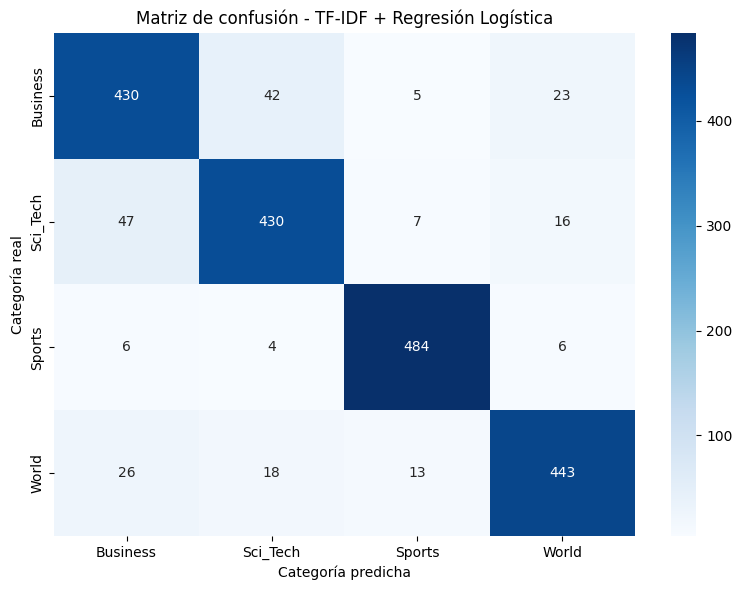

In [ ]:

# PASO 7: Matriz de confusión

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

etiquetas = sorted(y_test.unique())

matriz = confusion_matrix(
    y_test,
    y_pred,
    labels=etiquetas
)

plt.figure(figsize=(8, 6))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas
)

plt.title("Matriz de confusión - TF-IDF + Regresión Logística")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.tight_layout()
plt.show()


In [ ]:

# PASO 9: Identificar las principales confusiones

import numpy as np
import pandas as pd

errores = matriz.copy()
np.fill_diagonal(errores, 0)

confusiones = []

for i, categoria_real in enumerate(etiquetas):
    for j, categoria_predicha in enumerate(etiquetas):
        if errores[i, j] > 0:
            confusiones.append({
                "Categoría real": categoria_real,
                "Predicha como": categoria_predicha,
                "Cantidad": int(errores[i, j])
            })

confusiones_df = pd.DataFrame(confusiones)
confusiones_df = confusiones_df.sort_values(
    "Cantidad", ascending=False
).reset_index(drop=True)

display(confusiones_df.head(10))


,Categoría real,Predicha como,Cantidad
0,Sci_Tech,Business,47
1,Business,Sci_Tech,42
2,World,Business,26
3,Business,World,23
4,World,Sci_Tech,18
5,Sci_Tech,World,16
6,World,Sports,13
7,Sci_Tech,Sports,7
8,Sports,World,6
9,Sports,Business,6


In [ ]:

# PASO 10: Comparación de configuraciones TF-IDF

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

configuraciones = [
    {"max_features": 10000, "ngram_range": (1, 1)},
    {"max_features": 20000, "ngram_range": (1, 2)},
    {"max_features": 50000, "ngram_range": (1, 2)}
]

resultados = []

for config in configuraciones:
    print("Evaluando:", config)

    vectorizador_exp = TfidfVectorizer(
        max_features=config["max_features"],
        ngram_range=config["ngram_range"],
        min_df=2,
        sublinear_tf=True
    )

    # El vectorizador aprende únicamente del entrenamiento
    X_train_exp = vectorizador_exp.fit_transform(X_train)
    X_test_exp = vectorizador_exp.transform(X_test)

    modelo_exp = LogisticRegression(
        max_iter=1000,
        random_state=42
    )

    modelo_exp.fit(X_train_exp, y_train)
    pred_exp = modelo_exp.predict(X_test_exp)

    resultados.append({
        "max_features": config["max_features"],
        "ngram_range": str(config["ngram_range"]),
        "accuracy": accuracy_score(y_test, pred_exp),
        "f1_macro": f1_score(
            y_test, pred_exp, average="macro"
        ),
        "caracteristicas_reales": len(
            vectorizador_exp.get_feature_names_out()
        )
    })

resultados_df = pd.DataFrame(resultados)
resultados_df = resultados_df.sort_values(
    "accuracy", ascending=False
).reset_index(drop=True)

display(resultados_df)


Evaluando: {'max_features': 10000, 'ngram_range': (1, 1)}
Evaluando: {'max_features': 20000, 'ngram_range': (1, 2)}
Evaluando: {'max_features': 50000, 'ngram_range': (1, 2)}


,max_features,ngram_range,accuracy,f1_macro,caracteristicas_reales
0,10000,"(1, 1)",0.8985,0.898483,9493
1,20000,"(1, 2)",0.8935,0.893412,20000
2,50000,"(1, 2)",0.8930,0.892962,26335


In [ ]:

# PASO 11: Guardar la comparación en Excel

archivo = "Comparacion_TFIDF_AG_News.xlsx"

resultados_df.to_excel(archivo, index=False)

from google.colab import files
files.download(archivo)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Comparación de configuraciones TF-IDF

Se compararon tres configuraciones de TF-IDF utilizando Regresión Logística. La configuración con 10.000 características y unigramas obtuvo el mejor resultado, con un accuracy de 89,85 % y un F1 macro de 0,8985.

Las configuraciones con unigramas y bigramas alcanzaron accuracies de 89,35 % y 89,30 %, respectivamente. En estos experimentos, la incorporación de bigramas no produjo una mejora en el desempeño. Por este motivo, se selecciona como candidata la configuración de 10.000 características y unigramas.


In [ ]:

# PASO 13: Entrenar y evaluar el modelo definitivo

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

# Configuración seleccionada en los experimentos
vectorizador_final = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 1),
    min_df=2,
    sublinear_tf=True
)

# Ajustar solo con entrenamiento y transformar test
X_train_final = vectorizador_final.fit_transform(X_train)
X_test_final = vectorizador_final.transform(X_test)

# Entrenar el clasificador
modelo_final = LogisticRegression(
    max_iter=1000,
    random_state=42
)

modelo_final.fit(X_train_final, y_train)

# Generar predicciones finales
pred_final = modelo_final.predict(X_test_final)

# Evaluar el modelo
print(f"Accuracy final: {accuracy_score(y_test, pred_final):.4f}")
print("\nReporte de clasificación:")
print(classification_report(y_test, pred_final, zero_division=0))


Accuracy final: 0.8985

Reporte de clasificación:
              precision    recall  f1-score   support

    Business       0.86      0.86      0.86       500
    Sci_Tech       0.87      0.88      0.87       500
      Sports       0.96      0.97      0.96       500
       World       0.91      0.89      0.90       500

    accuracy                           0.90      2000
   macro avg       0.90      0.90      0.90      2000
weighted avg       0.90      0.90      0.90      2000



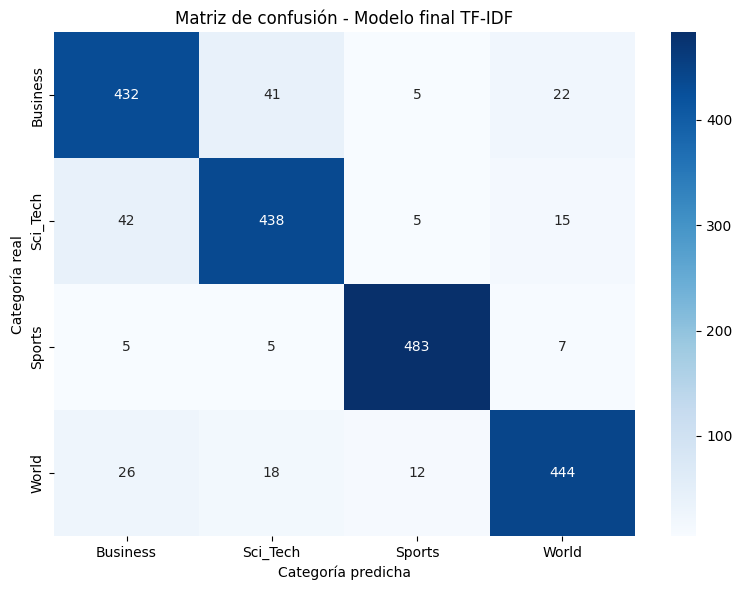

In [ ]:

# PASO 14: Matriz de confusión del modelo definitivo

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

etiquetas_final = sorted(y_test.unique())

matriz_final = confusion_matrix(
    y_test,
    pred_final,
    labels=etiquetas_final
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    matriz_final,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=etiquetas_final,
    yticklabels=etiquetas_final
)

plt.title("Matriz de confusión - Modelo final TF-IDF")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.tight_layout()
plt.show()


### Evaluación del modelo definitivo

El modelo definitivo utiliza TF-IDF con un máximo de 10.000 características y unigramas (`ngram_range=(1,1)`), junto con un clasificador de Regresión Logística.

Se obtuvo una exactitud (*accuracy*) de **89,85 %** sobre los 2.000 registros del conjunto de prueba. El promedio macro de F1 fue aproximadamente **0,90**, lo que refleja un buen desempeño general entre las cuatro categorías.

La categoría **Sports** presentó el mejor desempeño, con un F1-score de 0,96 y un recall de 0,97. En cambio, **Business** obtuvo un F1-score de 0,86, por lo que constituye una de las categorías con mayor margen de mejora.

En comparación con las configuraciones anteriores, el modelo con 10.000 características y unigramas obtuvo el mejor resultado. Esto muestra que aumentar la cantidad de características e incorporar bigramas no necesariamente mejora el desempeño del clasificador.

En conclusión, el modelo permite clasificar noticias en Business, Sci_Tech, Sports y World con un buen nivel de precisión, aunque todavía existen errores de clasificación entre algunas categorías.

In [ ]:
from sklearn.metrics import confusion_matrix
import pandas as pd

etiquetas_final = sorted(y_test.unique())

matriz_final = confusion_matrix(
    y_test,
    pred_final,
    labels=etiquetas_final
)

matriz_df = pd.DataFrame(
    matriz_final,
    index=etiquetas_final,
    columns=etiquetas_final
)

print("Matriz de confusión:")
display(matriz_df)

Matriz de confusión:


,Business,Sci_Tech,Sports,World
Business,432,41,5,22
Sci_Tech,42,438,5,15
Sports,5,5,483,7
World,26,18,12,444


### Análisis de la matriz de confusión

La matriz de confusión permite identificar los aciertos y errores del clasificador para cada categoría de noticias. El modelo clasificó correctamente 1.797 de las 2.000 noticias del conjunto de prueba, alcanzando una exactitud global del 89,85 %.

La categoría Sports presentó el mejor desempeño, con 483 noticias correctamente clasificadas de un total de 500. En contraste, Business obtuvo 432 aciertos y mostró una confusión importante con Sci_Tech, mientras que World presentó errores principalmente hacia Business.

Los errores más frecuentes se observaron entre Business y Sci_Tech, con 41 noticias de Business clasificadas como Sci_Tech y 42 noticias de Sci_Tech clasificadas como Business. Esto sugiere que ambas categorías comparten vocabulario o temáticas que dificultan su diferenciación mediante el modelo.

En conclusión, el clasificador presenta un buen rendimiento general, aunque podría mejorarse trabajando sobre las características del texto y probando otras configuraciones del vectorizador o del algoritmo de clasificación.

## Conclusiones finales

En este trabajo se desarrolló un clasificador supervisado de noticias utilizando técnicas de procesamiento de lenguaje natural (NLP) y representación vectorial TF-IDF. Para la clasificación se utilizó el algoritmo de Regresión Logística, con el objetivo de asignar cada noticia a una de cuatro categorías: Business, Sci_Tech, Sports y World.

Durante el desarrollo se realizó el preprocesamiento de los textos, incluyendo limpieza, lematización y eliminación de palabras vacías. Posteriormente, se transformaron los textos en vectores numéricos mediante TF-IDF y se compararon distintas configuraciones del vectorizador.

La configuración seleccionada, con 10.000 características y unigramas, obtuvo una exactitud del 89,85 % sobre el conjunto de prueba de 2.000 noticias. La matriz de confusión permitió identificar que Sports fue la categoría con mejor desempeño, mientras que las principales confusiones ocurrieron entre Business y Sci_Tech.

Los resultados muestran que TF-IDF combinado con Regresión Logística permite obtener un buen rendimiento en la clasificación automática de noticias. Como posibles mejoras futuras, se podrían probar otros algoritmos, ajustar los parámetros del modelo y evaluar representaciones del texto más avanzadas.

En síntesis, el trabajo permitió aplicar las principales etapas de un proceso de aprendizaje supervisado: preparación de datos, transformación de textos, entrenamiento, evaluación y análisis de resultados.

In [ ]:
import sys
import pandas as pd
import sklearn
import matplotlib
import seaborn
import nltk

print("Python:", sys.version)
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("matplotlib:", matplotlib.__version__)
print("seaborn:", seaborn.__version__)
print("nltk:", nltk.__version__)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
pandas: 2.2.3
scikit-learn: 1.6.1
matplotlib: 3.10.0
seaborn: 0.13.2
nltk: 3.9.1


In [ ]:
contenido_requirements = """pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
nltk==3.9.1
"""

with open("requirements.txt", "w", encoding="utf-8") as archivo:
    archivo.write(contenido_requirements)

print(contenido_requirements)

pandas==2.2.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2
nltk==3.9.1



In [ ]:
from google.colab import files
files.download("requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>